# Task 5 – Bước 2: Thống kê và mô tả dữ liệu (EDA) – FreshRetailNet-50K
**Chỉ dùng tập train** (28/03/2024 – 25/06/2024, 90 ngày, 50.000 chuỗi). Eval đã được kiểm tra cấu trúc ở notebook 1 và không dùng ở đây.

Quy ước đã xác định ở notebook 1:
- `hours_stock_status`: **1 = hết hàng**, 0 = còn hàng.
- `stock_hour6_22_cnt` = số giờ hết hàng trong **giờ 6..21 (16 giờ)** → khung giờ kinh doanh, mẫu số 16 giờ/ngày.
- Doanh số (`sale_amount`, `hours_sale`) đã **chuẩn hóa**, không có đơn vị thật → trục ghi "doanh số (đã chuẩn hóa)".
- `sale_amount` = tổng 24 giá trị `hours_sale`.

Nội dung:
1. Phân phối doanh số theo ngày, tỷ lệ doanh số = 0, mức khác biệt giữa các chuỗi
2. Thống kê hết hàng (ghi rõ mẫu số và khung giờ)
3. Biểu đồ doanh số theo thời gian, theo giờ trong ngày, theo ngày trong tuần
4. Minh họa một số chuỗi cùng trạng thái hết hàng
5. Doanh số theo giảm giá, khuyến mãi, ngày lễ, thời tiết (**quan hệ quan sát, không kết luận nhân quả**)
6. Tổng hợp số liệu chính

> Chạy lần lượt từng ô. Mỗi phần có ô **"Nhận xét"** để điền sau khi xem kết quả. Biểu đồ được lưu vào `FRN50K/figures`.

## 0. Kết nối Drive và nạp dữ liệu đã xử lý từ notebook 1

In [4]:
import os, sys, json
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/FRN50K'
else:
    BASE_DIR = os.environ.get('FRN_BASE', './FRN50K')

PROC_DIR = os.path.join(BASE_DIR, 'processed')
FIG_DIR  = os.path.join(BASE_DIR, 'figures')
TAB_DIR  = os.path.join(BASE_DIR, 'tables')
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

df = pd.read_parquet(os.path.join(PROC_DIR, 'train_daily.parquet'))
sale_h  = np.load(os.path.join(PROC_DIR, 'train_hours_sale.npy'))
stock_h = np.load(os.path.join(PROC_DIR, 'train_hours_stock.npy'))
assert len(df) == sale_h.shape[0] == stock_h.shape[0]

BIZ_LO, BIZ_HI = 6, 22          # giờ 6..21
N_BIZ = BIZ_HI - BIZ_LO         # 16 giờ
N_ROWS = len(df)
SALE_LABEL = 'Doanh số (đã chuẩn hóa)'

df['dow'] = df['dt'].dt.dayofweek            # 0 = Thứ Hai
df['is_weekend'] = df['dow'] >= 5
df['has_stockout'] = df['stock_hour6_22_cnt'] > 0
DOW_NAMES = ['T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'CN']

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})

def save_fig(fig, name):
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print('Đã lưu:', path)

def save_tab(t, name):
    t.to_csv(os.path.join(TAB_DIR, name), encoding='utf-8-sig')

KEY = {}   # số liệu chính để tổng hợp cuối notebook
print(df.shape, sale_h.shape, stock_h.shape)
pd.set_option('display.float_format', '{:,.4f}'.format)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(4500000, 20) (4500000, 24) (4500000, 24)


## 1. Phân phối doanh số theo ngày
Đơn vị quan sát: **một dòng = một cặp cửa hàng–sản phẩm trong một ngày** (4.500.000 dòng).

In [5]:
s = df['sale_amount']
q = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
desc = pd.concat([
    pd.Series({'Số dòng': len(s), 'Trung bình': s.mean(), 'Độ lệch chuẩn': s.std(),
               'Nhỏ nhất': s.min(), 'Lớn nhất': s.max(), 'Độ lệch (skewness)': s.skew()}),
    s.quantile(q).rename(lambda x: f'Phân vị {int(x*100)}%'),
]).to_frame('sale_amount (ngày)')
save_tab(desc, '1a_mo_ta_doanh_so_ngay.csv')
display(desc.round(4))

zero_day  = (s == 0).mean()
zero_hour = (sale_h == 0).mean()
zero_hour_biz = (sale_h[:, BIZ_LO:BIZ_HI] == 0).mean()
KEY['ty_le_ngay_doanh_so_0'] = zero_day
KEY['ty_le_gio_doanh_so_0_24h'] = zero_hour
print(f'Tỷ lệ dòng (cửa hàng–sản phẩm–ngày) có doanh số = 0: {zero_day:.2%}  (mẫu số: {N_ROWS:,} dòng)')
print(f'Tỷ lệ giờ có doanh số = 0 (24 giờ):            {zero_hour:.2%}  (mẫu số: {N_ROWS*24:,} giờ)')
print(f'Tỷ lệ giờ có doanh số = 0 (giờ 6..21):          {zero_hour_biz:.2%}  (mẫu số: {N_ROWS*N_BIZ:,} giờ)')

,sale_amount (ngày)
Số dòng,"4,500,000.0000"
Trung bình,0.9986
Độ lệch chuẩn,1.4067
Nhỏ nhất,0.0000
Lớn nhất,44.9000
Độ lệch (skewness),8.4718
Phân vị 1%,0.0000
Phân vị 5%,0.1000
Phân vị 10%,0.2000
Phân vị 25%,0.4000


Tỷ lệ dòng (cửa hàng–sản phẩm–ngày) có doanh số = 0: 4.46%  (mẫu số: 4,500,000 dòng)
Tỷ lệ giờ có doanh số = 0 (24 giờ):            77.78%  (mẫu số: 108,000,000 giờ)
Tỷ lệ giờ có doanh số = 0 (giờ 6..21):          69.06%  (mẫu số: 72,000,000 giờ)


Đã lưu: /content/drive/MyDrive/FRN50K/figures/1a_phan_phoi_doanh_so_ngay.png


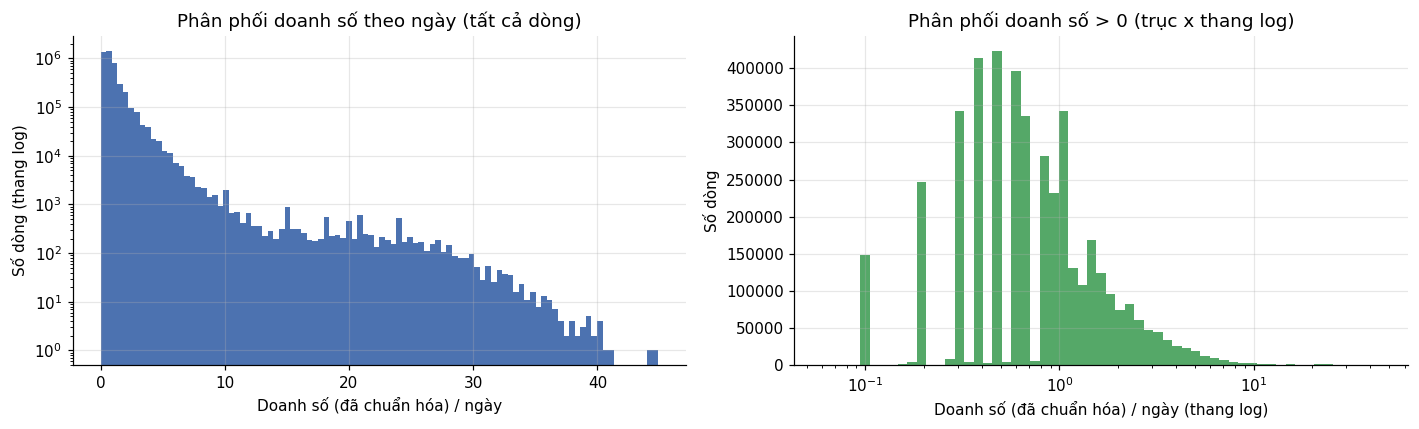

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pos = s[s > 0]
axes[0].hist(s, bins=100, color='#4C72B0')
axes[0].set_yscale('log')
axes[0].set_title('Phân phối doanh số theo ngày (tất cả dòng)')
axes[0].set_xlabel(SALE_LABEL + ' / ngày')
axes[0].set_ylabel('Số dòng (thang log)')

bins = np.logspace(np.log10(pos.min()), np.log10(pos.max()), 60)
axes[1].hist(pos, bins=bins, color='#55A868')
axes[1].set_xscale('log')
axes[1].set_title('Phân phối doanh số > 0 (trục x thang log)')
axes[1].set_xlabel(SALE_LABEL + ' / ngày (thang log)')
axes[1].set_ylabel('Số dòng')
fig.tight_layout(); save_fig(fig, '1a_phan_phoi_doanh_so_ngay.png'); plt.show()

### 1b. Doanh số = 0: do không có nhu cầu hay do hết hàng?
Ngày/giờ có doanh số 0 có thể là **nhu cầu thật bằng 0** hoặc **bị cắt cụt do hết hàng**.

In [6]:
ct = pd.crosstab(df['has_stockout'].map({True: 'Có ≥1 giờ hết hàng (6..21)', False: 'Không hết hàng (6..21)'}),
                 (s == 0).map({True: 'Doanh số = 0', False: 'Doanh số > 0'}),
                 margins=True, margins_name='Tổng')
ct_pct = pd.crosstab(df['has_stockout'], s == 0, normalize='index')
display(ct)
print('Tỷ lệ ngày doanh số = 0 khi KHÔNG hết hàng:', f"{ct_pct.loc[False, True]:.2%}")
print('Tỷ lệ ngày doanh số = 0 khi CÓ hết hàng:   ', f"{ct_pct.loc[True, True]:.2%}")
save_tab(ct, '1b_doanh_so_0_va_het_hang_ngay.csv')

# Theo giờ (24 giờ)
z = (sale_h == 0)
so = (stock_h == 1)
hz = pd.Series({
    'Tỷ lệ giờ doanh số = 0 khi còn hàng': z[~so].mean(),
    'Tỷ lệ giờ doanh số = 0 khi hết hàng': z[so].mean(),
    'Tỷ lệ giờ hết hàng trong các giờ có doanh số = 0': so[z].mean(),
    'Tỷ lệ giờ có doanh số > 0 dù đang hết hàng': (~z[so]).mean(),
}).to_frame('giá trị (mẫu số: giờ, 24 giờ/ngày)')
del z, so
save_tab(hz, '1b_doanh_so_0_va_het_hang_gio.csv')
hz.style.format('{:.2%}')

sale_amount,Doanh số = 0,Doanh số > 0,Tổng
has_stockout,,,
Có ≥1 giờ hết hàng (6..21),153816,1838190,1992006
Không hết hàng (6..21),46944,2461050,2507994
Tổng,200760,4299240,4500000


Tỷ lệ ngày doanh số = 0 khi KHÔNG hết hàng: 1.87%
Tỷ lệ ngày doanh số = 0 khi CÓ hết hàng:    7.72%


,"giá trị (mẫu số: giờ, 24 giờ/ngày)"
Tỷ lệ giờ doanh số = 0 khi còn hàng,71.36%
Tỷ lệ giờ doanh số = 0 khi hết hàng,97.13%
Tỷ lệ giờ hết hàng trong các giờ có doanh số = 0,31.08%
Tỷ lệ giờ có doanh số > 0 dù đang hết hàng,2.87%


### 1c. Mức độ khác biệt giữa các chuỗi
Tính trên mỗi chuỗi (90 ngày): doanh số trung bình/ngày, hệ số biến thiên (CV = độ lệch chuẩn / trung bình), tỷ lệ ngày doanh số 0, tỷ lệ giờ hết hàng.

In [7]:
df['is_zero'] = df['sale_amount'] == 0
g = df.groupby(['store_id', 'product_id'], sort=False)
ser = g.agg(city_id=('city_id', 'first'),
            first_category_id=('first_category_id', 'first'),
            mean_sale=('sale_amount', 'mean'),
            std_sale=('sale_amount', 'std'),
            total_sale=('sale_amount', 'sum'),
            zero_rate=('is_zero', 'mean'),
            stock_hours=('stock_hour6_22_cnt', 'sum'),
            n_days=('sale_amount', 'size'),
            stockout_days=('has_stockout', 'sum'))
ser['cv'] = ser['std_sale'] / ser['mean_sale'].replace(0, np.nan)
ser['stockout_rate'] = ser['stock_hours'] / (ser['n_days'] * N_BIZ)   # mẫu số: 90 ngày × 16 giờ
ser['stockout_day_rate'] = ser['stockout_days'] / ser['n_days']
print('Số chuỗi:', len(ser), '| số chuỗi có doanh số = 0 cả 90 ngày:', int((ser['total_sale'] == 0).sum()))

het = ser[['mean_sale', 'cv', 'zero_rate', 'stockout_rate']].describe(
    percentiles=[.1, .25, .5, .75, .9, .99]).T
het.index = ['Doanh số TB/ngày', 'Hệ số biến thiên (CV)', 'Tỷ lệ ngày doanh số 0',
             'Tỷ lệ giờ hết hàng (6..21)']
save_tab(het, '1c_khac_biet_giua_chuoi.csv')
display(het.round(4))

# Mức độ tập trung: top 20% chuỗi chiếm bao nhiêu % tổng doanh số
tot = np.sort(ser['total_sale'].to_numpy())[::-1]
cum = np.cumsum(tot) / tot.sum()
top20 = cum[int(0.2 * len(tot)) - 1]
KEY['top20_chuoi_chiem_ty_le_doanh_so'] = top20
ratio_p90_p10 = ser['mean_sale'].quantile(.9) / max(ser['mean_sale'].quantile(.1), 1e-12)
print(f'20% chuỗi bán nhiều nhất chiếm {top20:.1%} tổng doanh số')
print(f'Tỷ số doanh số TB giữa chuỗi phân vị 90% và 10%: {ratio_p90_p10:.1f} lần')
for col in ['product_id', 'store_id']:
    t = df.groupby(col)['sale_amount'].sum().sort_values(ascending=False)
    share = t.iloc[:int(0.2 * len(t))].sum() / t.sum()
    KEY[f'top20_{col}_chiem'] = share
    print(f'20% {col} bán nhiều nhất chiếm {share:.1%} tổng doanh số')

Số chuỗi: 50000 | số chuỗi có doanh số = 0 cả 90 ngày: 0


,count,mean,std,min,10%,25%,50%,75%,90%,99%,max
Doanh số TB/ngày,"50,000.0000",0.9986,1.1526,0.2220,0.4338,0.4942,0.6578,1.0544,1.8222,4.9478,19.0744
Hệ số biến thiên (CV),"50,000.0000",0.5665,0.2093,0.1643,0.3742,0.4308,0.5141,0.6414,0.8297,1.3321,3.0078
Tỷ lệ ngày doanh số 0,"50,000.0000",0.0446,0.0706,0.0000,0.0000,0.0000,0.0222,0.0556,0.1222,0.3444,0.7222
Tỷ lệ giờ hết hàng (6..21),"50,000.0000",0.1988,0.0821,0.0389,0.1306,0.1486,0.1767,0.2194,0.2889,0.5306,0.9701


20% chuỗi bán nhiều nhất chiếm 48.5% tổng doanh số
Tỷ số doanh số TB giữa chuỗi phân vị 90% và 10%: 4.2 lần
20% product_id bán nhiều nhất chiếm 87.0% tổng doanh số
20% store_id bán nhiều nhất chiếm 39.6% tổng doanh số


Đã lưu: /content/drive/MyDrive/FRN50K/figures/1c_khac_biet_giua_chuoi.png


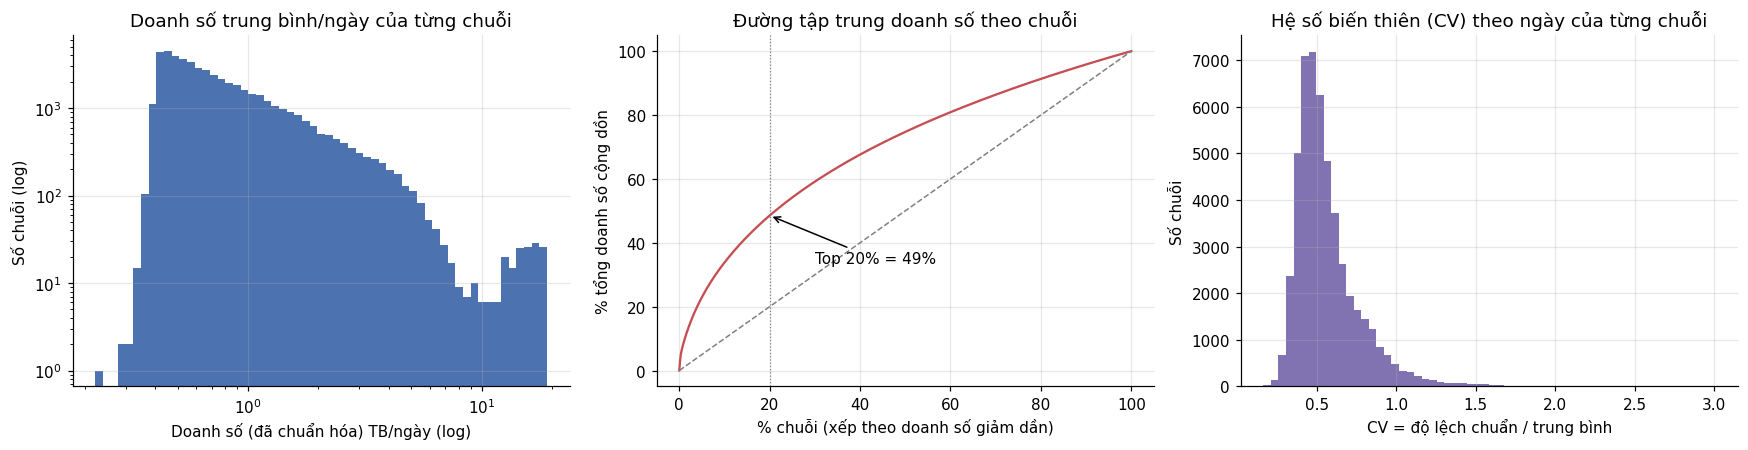

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
m = ser['mean_sale'][ser['mean_sale'] > 0]
axes[0].hist(m, bins=np.logspace(np.log10(m.min()), np.log10(m.max()), 60), color='#4C72B0')
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_title('Doanh số trung bình/ngày của từng chuỗi')
axes[0].set_xlabel(SALE_LABEL + ' TB/ngày (log)'); axes[0].set_ylabel('Số chuỗi (log)')

x = np.arange(1, len(cum) + 1) / len(cum)
axes[1].plot(x * 100, cum * 100, color='#C44E52')
axes[1].plot([0, 100], [0, 100], '--', color='gray', lw=1)
axes[1].axvline(20, color='gray', lw=0.8, ls=':')
axes[1].annotate(f'Top 20% = {top20:.0%}', (20, top20 * 100), xytext=(30, top20 * 100 - 15),
                 arrowprops=dict(arrowstyle='->'))
axes[1].set_title('Đường tập trung doanh số theo chuỗi')
axes[1].set_xlabel('% chuỗi (xếp theo doanh số giảm dần)'); axes[1].set_ylabel('% tổng doanh số cộng dồn')

axes[2].hist(ser['cv'].dropna(), bins=60, color='#8172B2')
axes[2].set_title('Hệ số biến thiên (CV) theo ngày của từng chuỗi')
axes[2].set_xlabel('CV = độ lệch chuẩn / trung bình'); axes[2].set_ylabel('Số chuỗi')
fig.tight_layout(); save_fig(fig, '1c_khac_biet_giua_chuoi.png'); plt.show()

**Nhận xét phần 1**
- **Phân phối doanh số ngày** (mẫu: 4.500.000 dòng cửa hàng–sản phẩm–ngày): trung bình 0,999, trung vị 0,7, độ lệch chuẩn 1,41, lớn nhất 44,9; skewness 8,47 → lệch phải mạnh, đuôi dài. 99% số dòng có doanh số ≤ 5,8. Các phân vị đều là bội số của 0,1 → doanh số ngày có vẻ được làm tròn đến 0,1 sau chuẩn hóa.
- **Tỷ lệ doanh số = 0:** 4,46% số ngày (mẫu số 4.500.000 dòng); 77,78% số giờ tính trên 24 giờ (mẫu số 108.000.000 giờ); 69,06% số giờ trong khung 6..21 (mẫu số 72.000.000 giờ) → dữ liệu theo ngày ít số 0 nhưng theo giờ rất thưa.
- **Số 0 và hết hàng:** 44,27% số ngày có ít nhất 1 giờ hết hàng (6..21). Tỷ lệ ngày doanh số = 0 là 7,72% khi có hết hàng so với 1,87% khi không hết hàng; 76,6% ngày doanh số = 0 rơi vào ngày có hết hàng → một phần lớn số 0 là doanh số bị cắt cụt chứ không phải nhu cầu bằng 0. Theo giờ: 97,13% giờ hết hàng có doanh số = 0; 2,87% giờ hết hàng vẫn có doanh số > 0 (có thể bán xong rồi mới hết trong cùng giờ).
- **Khác biệt giữa các chuỗi** (50.000 chuỗi): doanh số TB/ngày trung vị 0,66, chênh 4,2 lần giữa phân vị 90% và 10%; CV trung vị 0,51. Không có chuỗi nào bán 0 cả 90 ngày (nhỏ nhất 0,22/ngày) → dữ liệu có thể đã được lọc. Mọi chuỗi đều có hết hàng (tỷ lệ giờ hết hàng 3,9%–97%, trung vị 17,7%, TB 19,9%).
- **Mức độ tập trung:** 20% chuỗi chiếm 48,5% tổng doanh số; 20% sản phẩm chiếm 87%; 20% cửa hàng chiếm 39,6%. (Bài báo báo cáo top 20% SKU chiếm 51,8% *số giao dịch* – khác thước đo nên không so trực tiếp.)
- Biểu đồ phân phối doanh số TB/chuỗi có ngưỡng cắt rõ ở khoảng 0,4 (gần như không có chuỗi nào thấp hơn) → củng cố giả thuyết bộ dữ liệu đã lọc chuỗi; có một cụm nhỏ chuỗi bán rất nhiều (≈15–19/ngày) ở đuôi phải, có thể chi phối các chỉ số tính theo tổng như WAPE.
- CV của đa số chuỗi nằm trong khoảng 0,4–0,7; đuôi phải kéo đến khoảng 3 gồm một số ít chuỗi biến động rất mạnh...

## 2. Thống kê hết hàng
Hai cách tính, **luôn ghi kèm mẫu số và khung giờ**:
- **Khung giờ kinh doanh 6..21 (16 giờ)** – dùng `stock_hour6_22_cnt`, là khung giờ chính của bộ dữ liệu.
- **Cả ngày 24 giờ** – dùng `hours_stock_status`, để so sánh.

In [9]:
tot_biz = int(df['stock_hour6_22_cnt'].sum())
tot_24  = int(stock_h.sum())
outside = tot_24 - int(stock_h[:, BIZ_LO:BIZ_HI].sum())
day_any_24 = (stock_h.sum(axis=1) > 0).mean()

so_tab = pd.DataFrame([
    ['Tổng số giờ hết hàng', f'{tot_biz:,}', 'giờ 6..21', '—'],
    ['Tỷ lệ giờ hết hàng', f'{tot_biz / (N_ROWS * N_BIZ):.2%}', 'giờ 6..21',
        f'{N_ROWS:,} dòng × 16 giờ = {N_ROWS*N_BIZ:,} giờ'],
    ['Tỷ lệ ngày có ≥1 giờ hết hàng', f"{df['has_stockout'].mean():.2%}", 'giờ 6..21',
        f'{N_ROWS:,} cửa hàng–sản phẩm–ngày'],
    ['Tỷ lệ ngày hết hàng cả 16 giờ', f"{(df['stock_hour6_22_cnt'] == N_BIZ).mean():.2%}", 'giờ 6..21',
        f'{N_ROWS:,} cửa hàng–sản phẩm–ngày'],
    ['Số giờ hết hàng TB trong ngày có hết hàng',
        f"{df.loc[df['has_stockout'], 'stock_hour6_22_cnt'].mean():.2f}", 'giờ 6..21',
        f"{int(df['has_stockout'].sum()):,} ngày có hết hàng"],
    ['Tổng số giờ hết hàng', f'{tot_24:,}', '24 giờ', '—'],
    ['Tỷ lệ giờ hết hàng', f'{tot_24 / (N_ROWS * 24):.2%}', '24 giờ',
        f'{N_ROWS:,} dòng × 24 giờ = {N_ROWS*24:,} giờ'],
    ['Tỷ lệ ngày có ≥1 giờ hết hàng', f'{day_any_24:.2%}', '24 giờ', f'{N_ROWS:,} cửa hàng–sản phẩm–ngày'],
    ['Số giờ hết hàng nằm ngoài giờ 6..21', f'{outside:,} ({outside / max(tot_24, 1):.1%} tổng)', '0..5 và 22..23', '—'],
    ['Tỷ lệ chuỗi có ít nhất 1 giờ hết hàng (6..21)', f"{(ser['stock_hours'] > 0).mean():.2%}", 'giờ 6..21',
        f'{len(ser):,} chuỗi'],
], columns=['Chỉ tiêu', 'Giá trị', 'Khung giờ', 'Mẫu số']).set_index('Chỉ tiêu')
KEY['ty_le_gio_het_hang_6_21'] = tot_biz / (N_ROWS * N_BIZ)
KEY['ty_le_gio_het_hang_24h'] = tot_24 / (N_ROWS * 24)
KEY['ty_le_ngay_co_het_hang_6_21'] = df['has_stockout'].mean()
save_tab(so_tab, '2a_thong_ke_het_hang.csv')
so_tab

,Giá trị,Khung giờ,Mẫu số
Chỉ tiêu,,,
Tổng số giờ hết hàng,"14,311,536",giờ 6..21,—
Tỷ lệ giờ hết hàng,19.88%,giờ 6..21,"4,500,000 dòng × 16 giờ = 72,000,000 giờ"
Tỷ lệ ngày có ≥1 giờ hết hàng,44.27%,giờ 6..21,"4,500,000 cửa hàng–sản phẩm–ngày"
Tỷ lệ ngày hết hàng cả 16 giờ,4.04%,giờ 6..21,"4,500,000 cửa hàng–sản phẩm–ngày"
Số giờ hết hàng TB trong ngày có hết hàng,7.18,giờ 6..21,"1,992,006 ngày có hết hàng"
Tổng số giờ hết hàng,"26,876,404",24 giờ,—
Tỷ lệ giờ hết hàng,24.89%,24 giờ,"4,500,000 dòng × 24 giờ = 108,000,000 giờ"
Tỷ lệ ngày có ≥1 giờ hết hàng,60.02%,24 giờ,"4,500,000 cửa hàng–sản phẩm–ngày"
Số giờ hết hàng nằm ngoài giờ 6..21,"12,564,868 (46.8% tổng)",0..5 và 22..23,—


Đã lưu: /content/drive/MyDrive/FRN50K/figures/2a_het_hang_phan_phoi_va_theo_gio.png


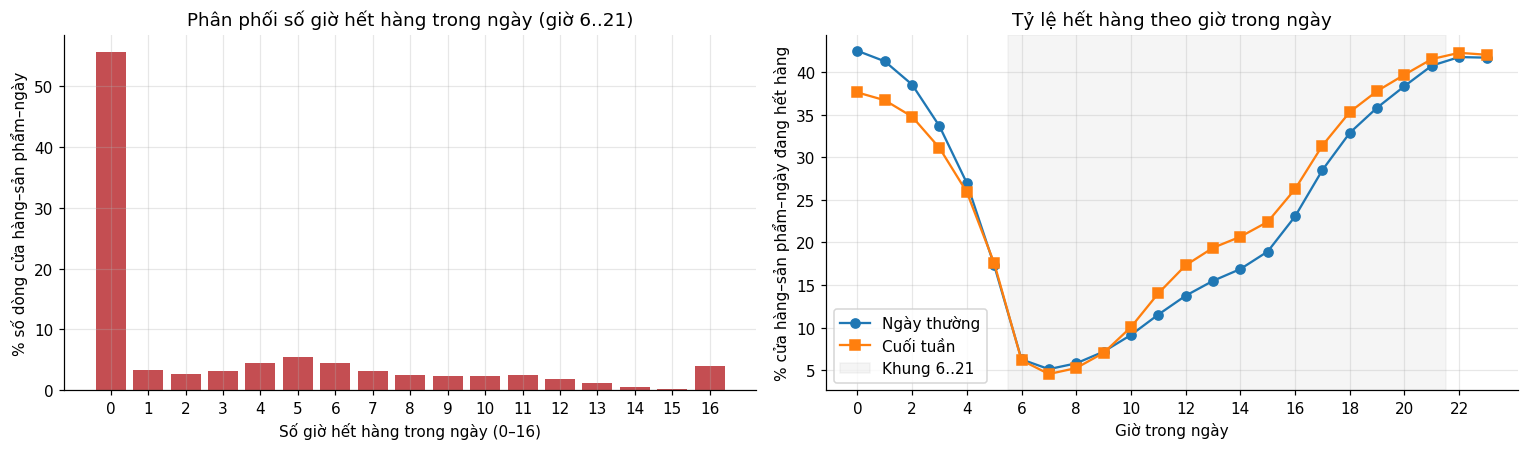

Mẫu số mỗi giờ: 4,500,000 cửa hàng–sản phẩm–ngày
Giờ hết hàng thấp nhất: 7 (5.0%) | cao nhất: 22 (41.9%)


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
vc = df['stock_hour6_22_cnt'].value_counts().sort_index()
axes[0].bar(vc.index, vc.values / N_ROWS * 100, color='#C44E52')
axes[0].set_title('Phân phối số giờ hết hàng trong ngày (giờ 6..21)')
axes[0].set_xlabel('Số giờ hết hàng trong ngày (0–16)')
axes[0].set_ylabel('% số dòng cửa hàng–sản phẩm–ngày')
axes[0].set_xticks(range(0, 17))

hr_rate = stock_h.mean(axis=0) * 100
wk = df['is_weekend'].to_numpy()
axes[1].plot(range(24), stock_h[~wk].mean(axis=0) * 100, marker='o', label='Ngày thường')
axes[1].plot(range(24), stock_h[wk].mean(axis=0) * 100, marker='s', label='Cuối tuần')
axes[1].axvspan(BIZ_LO - 0.5, BIZ_HI - 0.5, color='gray', alpha=0.08, label='Khung 6..21')
axes[1].set_title('Tỷ lệ hết hàng theo giờ trong ngày')
axes[1].set_xlabel('Giờ trong ngày'); axes[1].set_ylabel('% cửa hàng–sản phẩm–ngày đang hết hàng')
axes[1].set_xticks(range(0, 24, 2)); axes[1].legend()
fig.tight_layout(); save_fig(fig, '2a_het_hang_phan_phoi_va_theo_gio.png'); plt.show()

hr_tab = pd.DataFrame({'ty_le_het_hang_%': hr_rate.round(2)}, index=pd.Index(range(24), name='gio'))
save_tab(hr_tab, '2a_ty_le_het_hang_theo_gio.csv')
print('Mẫu số mỗi giờ:', f'{N_ROWS:,}', 'cửa hàng–sản phẩm–ngày')
print('Giờ hết hàng thấp nhất:', int(hr_rate.argmin()), f'({hr_rate.min():.1f}%)',
      '| cao nhất:', int(hr_rate.argmax()), f'({hr_rate.max():.1f}%)')

Đã lưu: /content/drive/MyDrive/FRN50K/figures/2b_het_hang_theo_nhom.png


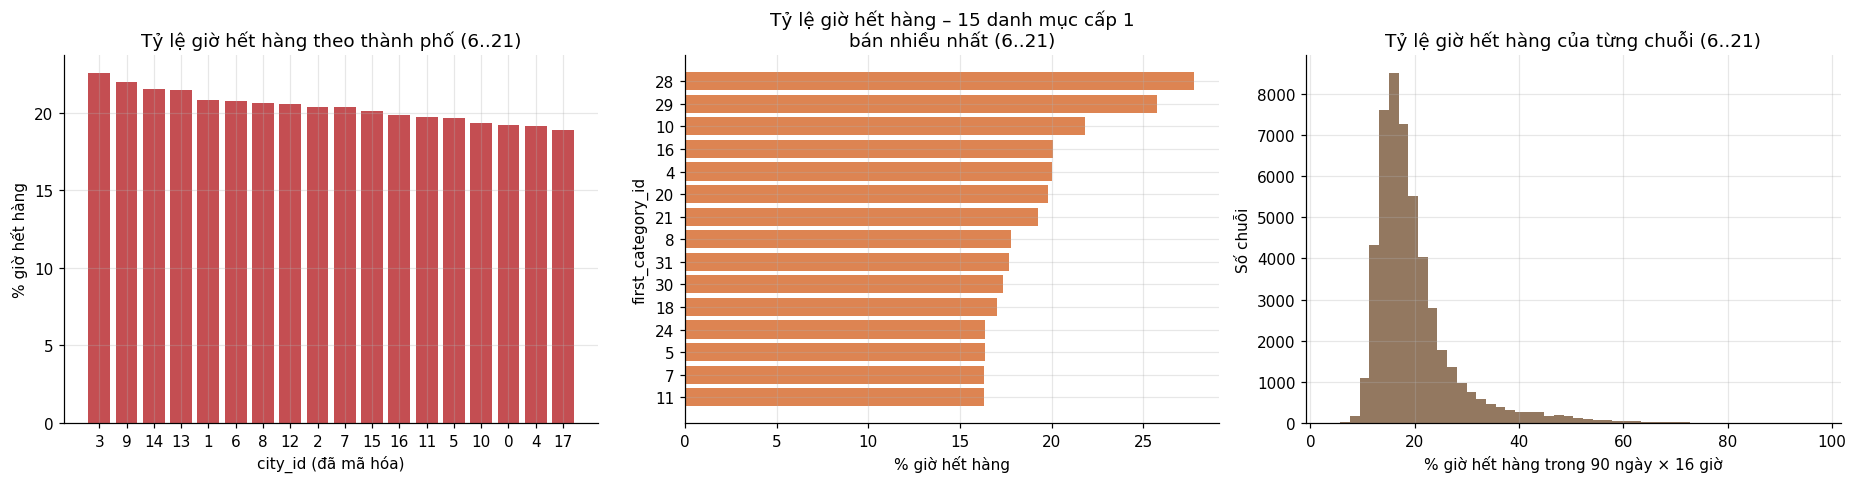

,so_dong,ty_le_gio_het_6_21,ngay_co_het
city_id,,,
3,238320,0.2256,0.4102
9,17730,0.2200,0.5140
14,44370,0.2150,0.4522
13,210240,0.2144,0.4721
1,40590,0.2080,0.4816
6,214560,0.2073,0.4491
8,5850,0.2060,0.3757
12,460530,0.2058,0.4478
2,36630,0.2039,0.5029


In [12]:
# Theo thành phố và danh mục cấp 1 (mẫu số: số dòng × 16 giờ của nhóm)
def stock_by(col):
    t = df.groupby(col).agg(so_dong=('stock_hour6_22_cnt', 'size'),
                            gio_het=('stock_hour6_22_cnt', 'sum'),
                            ngay_co_het=('has_stockout', 'mean'),
                            doanh_so=('sale_amount', 'sum'))
    t['ty_le_gio_het_6_21'] = t['gio_het'] / (t['so_dong'] * N_BIZ)
    t['ty_trong_doanh_so'] = t['doanh_so'] / t['doanh_so'].sum()
    return t.sort_values('ty_le_gio_het_6_21', ascending=False)

by_city = stock_by('city_id'); by_cat = stock_by('first_category_id')
save_tab(by_city, '2b_het_hang_theo_thanh_pho.csv'); save_tab(by_cat, '2b_het_hang_theo_danh_muc1.csv')

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].bar(by_city.index.astype(str), by_city['ty_le_gio_het_6_21'] * 100, color='#C44E52')
axes[0].set_title('Tỷ lệ giờ hết hàng theo thành phố (6..21)')
axes[0].set_xlabel('city_id (đã mã hóa)'); axes[0].set_ylabel('% giờ hết hàng')

top = by_cat.sort_values('ty_trong_doanh_so', ascending=False).head(15).sort_values('ty_le_gio_het_6_21')
axes[1].barh(top.index.astype(str), top['ty_le_gio_het_6_21'] * 100, color='#DD8452')
axes[1].set_title('Tỷ lệ giờ hết hàng – 15 danh mục cấp 1\nbán nhiều nhất (6..21)')
axes[1].set_xlabel('% giờ hết hàng'); axes[1].set_ylabel('first_category_id')

axes[2].hist(ser['stockout_rate'] * 100, bins=50, color='#937860')
axes[2].set_title('Tỷ lệ giờ hết hàng của từng chuỗi (6..21)')
axes[2].set_xlabel('% giờ hết hàng trong 90 ngày × 16 giờ'); axes[2].set_ylabel('Số chuỗi')
fig.tight_layout(); save_fig(fig, '2b_het_hang_theo_nhom.png'); plt.show()
display(by_city[['so_dong', 'ty_le_gio_het_6_21', 'ngay_co_het']].round(4))

**Nhận xét phần 2**
- **Mức hết hàng chung (khung chính: giờ 6..21):** 14.311.536 giờ hết hàng, chiếm 19,88% tổng số giờ (mẫu số 4.500.000 dòng × 16 giờ = 72.000.000 giờ). 44,27% số cửa hàng–sản phẩm–ngày có ít nhất 1 giờ hết hàng (mẫu số 4.500.000); 4,04% hết hàng cả 16 giờ; ngày có hết hàng trung bình hết 7,18 giờ. 100% trong 50.000 chuỗi có ít nhất 1 giờ hết hàng.
- **So sánh 24 giờ:** tỷ lệ giờ hết hàng 24,89% (mẫu số 108.000.000 giờ), 60,02% số ngày có hết hàng. 46,8% số giờ hết hàng nằm ngoài khung 6..21 (0..5h, 22..23h) – lúc gần như không có doanh số – nên dùng khung 6..21 làm chỉ số chính để không thổi phồng tỷ lệ hết hàng.
- **Theo giờ trong ngày:** dạng chữ U – cao vào ban đêm (khoảng 38–42%), giảm mạnh lúc 5–6h (có thể do nhập hàng), thấp nhất lúc 7h (5,0%), tăng dần trong ngày và cao nhất lúc 22h (41,9%). Từ khoảng 10h–20h cuối tuần có tỷ lệ hết hàng cao hơn ngày thường. Mẫu số mỗi giờ: 4.500.000 cửa hàng–sản phẩm–ngày. Hình dạng giống bài báo nhưng mức khác (bài báo: <2% sau 6h, đỉnh 26% lúc 20h).
- **Phân phối số giờ hết hàng/ngày:** 56% số ngày không hết hàng; có đỉnh nhỏ ở 16 giờ (4%) – các ngày hết hàng suốt khung kinh doanh.
- **Theo nhóm:** giữa các thành phố tỷ lệ giờ hết hàng khá đồng đều (18,9%–22,6%); 15 danh mục cấp 1 bán nhiều nhất dao động khoảng 16%–22%. Theo chuỗi, đa số nằm ở 15–20%, đuôi phải đến khoảng 97%.
- **Mất cân đối dữ liệu:** thành phố 0 chiếm 2.322.990 dòng (51,6%) → kết quả tổng hợp chịu ảnh hưởng lớn bởi một thành phố.

## 3. Doanh số theo thời gian, theo giờ trong ngày, theo ngày trong tuần

holiday_flag có giống nhau cho mọi dòng trong cùng ngày không? True
Các ngày có holiday_flag = 1: ['2024-03-30', '2024-03-31', '2024-04-04', '2024-04-05', '2024-04-06', '2024-04-13', '2024-04-14', '2024-04-20', '2024-04-21', '2024-04-27', '2024-04-28', '2024-05-01', '2024-05-02', '2024-05-03', '2024-05-04', '2024-05-05', '2024-05-11', '2024-05-12', '2024-05-18', '2024-05-19', '2024-05-25', '2024-05-26', '2024-06-01', '2024-06-02', '2024-06-08', '2024-06-09', '2024-06-10', '2024-06-15', '2024-06-16', '2024-06-22', '2024-06-23']
Đã lưu: /content/drive/MyDrive/FRN50K/figures/3a_doanh_so_theo_thoi_gian.png


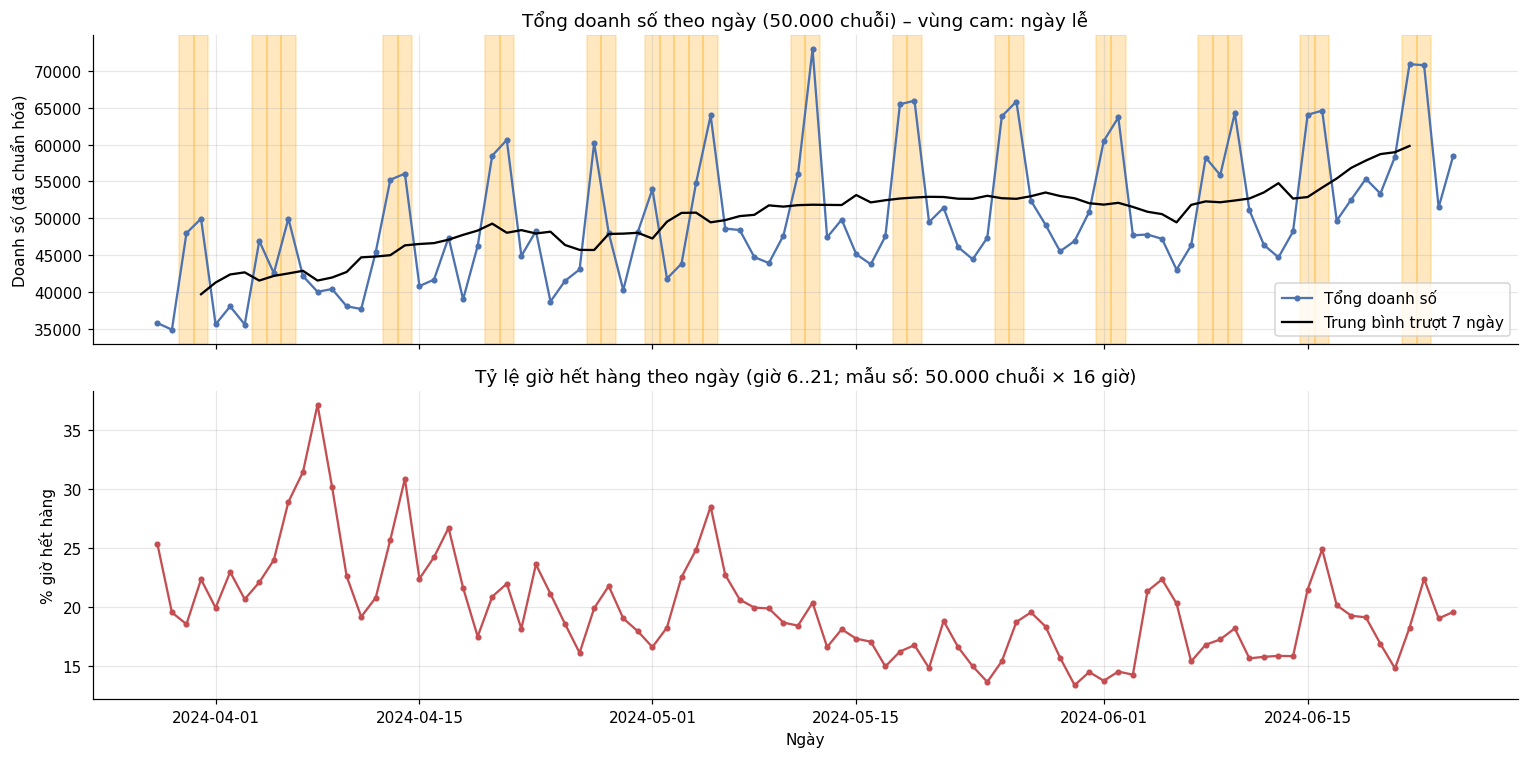

In [13]:
daily = df.groupby('dt').agg(tong_doanh_so=('sale_amount', 'sum'),
                             gio_het=('stock_hour6_22_cnt', 'sum'),
                             so_dong=('sale_amount', 'size'),
                             holiday=('holiday_flag', 'mean'),
                             activity=('activity_flag', 'mean'))
daily['ty_le_het_hang'] = daily['gio_het'] / (daily['so_dong'] * N_BIZ)
save_tab(daily, '3a_theo_ngay.csv')
print('holiday_flag có giống nhau cho mọi dòng trong cùng ngày không?',
      bool(daily['holiday'].isin([0, 1]).all()))
print('Các ngày có holiday_flag = 1:', [d.date().isoformat() for d in daily.index[daily['holiday'] > 0]])

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(daily.index, daily['tong_doanh_so'], marker='.', color='#4C72B0', label='Tổng doanh số')
axes[0].plot(daily.index, daily['tong_doanh_so'].rolling(7, center=True).mean(), color='black', lw=1.5,
             label='Trung bình trượt 7 ngày')
for d in daily.index[daily['holiday'] > 0.5]:
    axes[0].axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color='orange', alpha=0.25)
axes[0].set_title('Tổng doanh số theo ngày (50.000 chuỗi) – vùng cam: ngày lễ')
axes[0].set_ylabel(SALE_LABEL); axes[0].legend()

axes[1].plot(daily.index, daily['ty_le_het_hang'] * 100, color='#C44E52', marker='.')
axes[1].set_title('Tỷ lệ giờ hết hàng theo ngày (giờ 6..21; mẫu số: 50.000 chuỗi × 16 giờ)')
axes[1].set_ylabel('% giờ hết hàng'); axes[1].set_xlabel('Ngày')
fig.tight_layout(); save_fig(fig, '3a_doanh_so_theo_thoi_gian.png'); plt.show()

Đã lưu: /content/drive/MyDrive/FRN50K/figures/3b_doanh_so_theo_gio.png


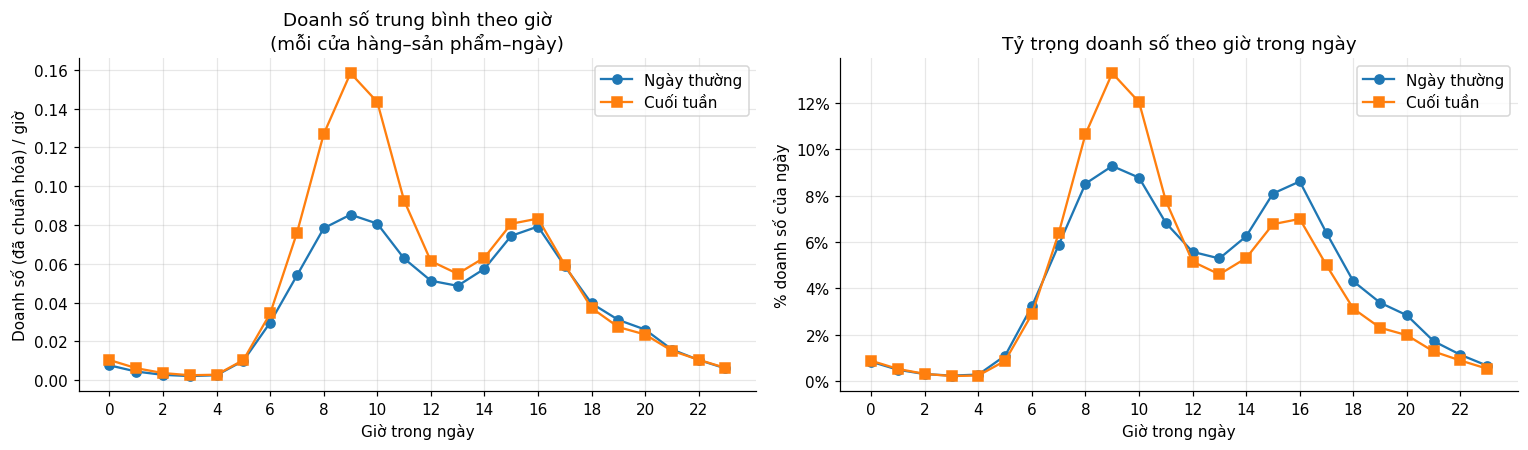

Ngày thường: 3 giờ bán nhiều nhất = [9, 10, 16]
Cuối tuần: 3 giờ bán nhiều nhất = [9, 10, 8]


In [14]:
# Theo giờ trong ngày: doanh số TB mỗi giờ, tách ngày thường / cuối tuần
wk = df['is_weekend'].to_numpy()
prof = pd.DataFrame({'Ngày thường': sale_h[~wk].mean(axis=0),
                     'Cuối tuần': sale_h[wk].mean(axis=0)}, index=pd.Index(range(24), name='gio'))
share = prof / prof.sum() * 100
save_tab(prof, '3b_doanh_so_theo_gio.csv')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for c, mk in zip(prof.columns, ['o', 's']):
    axes[0].plot(prof.index, prof[c], marker=mk, label=c)
    axes[1].plot(share.index, share[c], marker=mk, label=c)
axes[0].set_title('Doanh số trung bình theo giờ\n(mỗi cửa hàng–sản phẩm–ngày)')
axes[0].set_ylabel(SALE_LABEL + ' / giờ')
axes[1].set_title('Tỷ trọng doanh số theo giờ trong ngày')
axes[1].set_ylabel('% doanh số của ngày'); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
for ax in axes:
    ax.set_xlabel('Giờ trong ngày'); ax.set_xticks(range(0, 24, 2)); ax.legend()
fig.tight_layout(); save_fig(fig, '3b_doanh_so_theo_gio.png'); plt.show()
for c in prof.columns:
    top3 = prof[c].sort_values(ascending=False).index[:3].tolist()
    print(f'{c}: 3 giờ bán nhiều nhất = {top3}')

Đã lưu: /content/drive/MyDrive/FRN50K/figures/3c_doanh_so_theo_thu.png


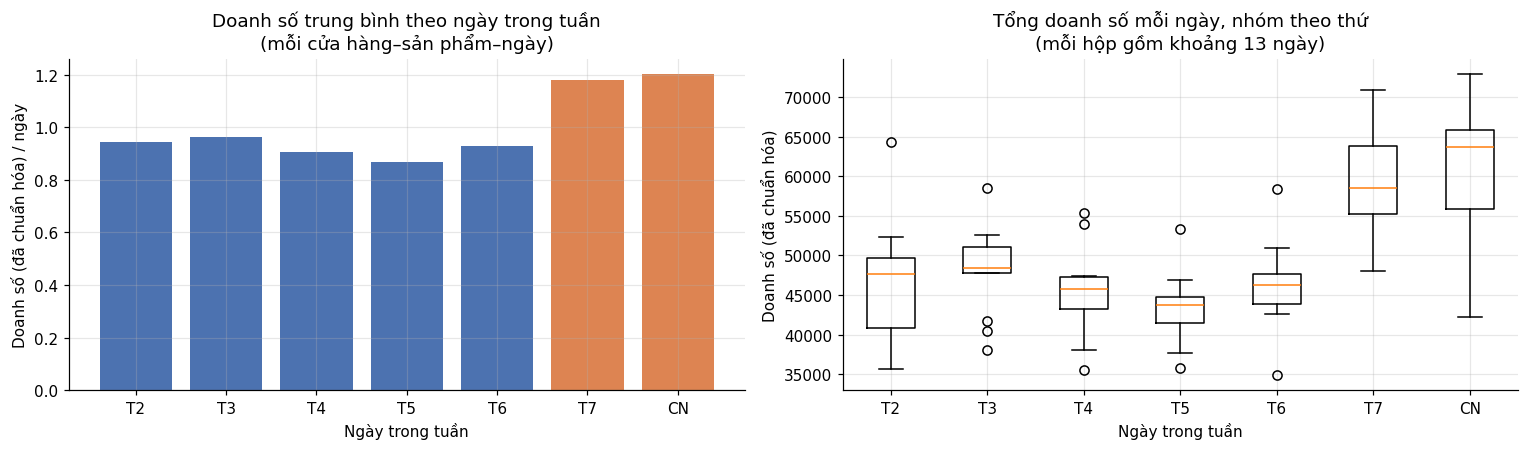

,doanh_so_tb,ty_le_het_hang,so_ngay,chi_so_so_voi_TB
T2,0.9426,0.2015,13,0.9439
T3,0.9620,0.2081,13,0.9633
T4,0.9069,0.1953,12,0.9082
T5,0.8660,0.1871,13,0.8673
T6,0.9268,0.1755,13,0.9281
T7,1.1781,0.1992,13,1.1798
CN,1.2007,0.2244,13,1.2024


In [15]:
# Theo ngày trong tuần
dow_tab = df.groupby('dow').agg(doanh_so_tb=('sale_amount', 'mean'),
                                ty_le_het_hang=('stock_hour6_22_cnt', lambda x: x.sum() / (len(x) * N_BIZ)),
                                so_ngay=('dt', 'nunique'))
dow_tab.index = DOW_NAMES
dow_tab['chi_so_so_voi_TB'] = dow_tab['doanh_so_tb'] / df['sale_amount'].mean()
save_tab(dow_tab, '3c_theo_thu_trong_tuan.csv')

daily['dow'] = daily.index.dayofweek
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].bar(DOW_NAMES, dow_tab['doanh_so_tb'], color=['#4C72B0'] * 5 + ['#DD8452'] * 2)
axes[0].set_title('Doanh số trung bình theo ngày trong tuần\n(mỗi cửa hàng–sản phẩm–ngày)')
axes[0].set_ylabel(SALE_LABEL + ' / ngày'); axes[0].set_xlabel('Ngày trong tuần')
axes[1].boxplot([daily.loc[daily['dow'] == d, 'tong_doanh_so'] for d in range(7)])
axes[1].set_xticks(range(1, 8)); axes[1].set_xticklabels(DOW_NAMES)
axes[1].set_title('Tổng doanh số mỗi ngày, nhóm theo thứ\n(mỗi hộp gồm khoảng 13 ngày)')
axes[1].set_ylabel(SALE_LABEL); axes[1].set_xlabel('Ngày trong tuần')
fig.tight_layout(); save_fig(fig, '3c_doanh_so_theo_thu.png'); plt.show()
dow_tab.round(4)

**Nhận xét phần 3**
- **Theo thời gian:** tổng doanh số ngày (50.000 chuỗi) có xu hướng tăng rõ trong 90 ngày – trung bình trượt 7 ngày tăng từ khoảng 40.000 (đầu tháng 4) lên khoảng 60.000 (cuối tháng 6), tức tăng khoảng 50%. Chu kỳ tuần rất rõ: các đỉnh rơi vào cuối tuần/ngày nghỉ (vùng cam). Đỉnh cao nhất khoảng 73.000 vào đầu tháng 5 (kỳ nghỉ Lao động 1–5/5).
- **Tỷ lệ giờ hết hàng theo ngày** (giờ 6..21; mẫu số 50.000 chuỗi × 16 giờ): cao hơn vào đầu kỳ (đỉnh khoảng 37% khoảng 7–8/4, ngay sau kỳ nghỉ Thanh Minh) rồi giảm dần, dao động quanh 15–20% từ giữa tháng 5. Hết hàng giảm trong khi doanh số tăng → một phần mức tăng doanh số quan sát được có thể do doanh số ít bị cắt cụt hơn, không hoàn toàn do nhu cầu tăng.
- **`holiday_flag`** đánh dấu gần như tất cả ngày cuối tuần cộng các kỳ nghỉ lễ (Thanh Minh 4–6/4, Lao động 1–5/5) → đây là cờ "ngày nghỉ", trùng lặp mạnh với cuối tuần.
- **Theo giờ trong ngày:** doanh số gần bằng 0 từ 0h–5h, tăng từ 6h. Ngày thường có hai đỉnh gần bằng nhau lúc 9h (khoảng 9% doanh số của ngày) và 16h (khoảng 8,5%). Cuối tuần có một đỉnh sáng mạnh hơn hẳn lúc 9h (khoảng 13%, doanh số/giờ gần gấp đôi ngày thường) và đỉnh chiều thấp hơn. Kết quả khớp với mô tả của bài báo (ngày thường hai đỉnh 9h và 16h; cuối tuần đỉnh sáng 9h mạnh hơn).
- **Theo ngày trong tuần:** doanh số TB/cửa hàng–sản phẩm–ngày ở T7 (1,178) và CN (1,201) cao hơn mức trung bình chung 18–20%; các ngày trong tuần ở mức 0,87–0,96, thấp nhất T5. Biểu đồ hộp cho thấy cuối tuần cũng biến động mạnh hơn. Tỷ lệ giờ hết hàng cao nhất ở CN (22,4%) và thấp nhất ở T6 (17,6%). Mỗi thứ có 13 ngày quan sát, riêng T4 có 12 ngày (90 ngày không chia hết cho 7).

## 4. Minh họa một số chuỗi cùng trạng thái hết hàng
Chọn 4 chuỗi đại diện theo tiêu chí cố định (`random_state=42` để chạy lại ra cùng kết quả):
- **A** – bán chạy, ít hết hàng; **B** – hết hàng thường xuyên; **C** – bán thưa (nhiều ngày doanh số 0); **D** – chuỗi điển hình (gần trung vị).

In [19]:
rng_state = 42
med = ser['mean_sale'].median()
hi = ser[ser['mean_sale'] >= ser['mean_sale'].quantile(.9)]          # 10% chuỗi bán chạy nhất
cands = {
    'A – bán chạy, ít hết hàng': hi[hi['stockout_rate'] <= hi['stockout_rate'].quantile(.1)],
    'B – hết hàng thường xuyên': ser[(ser['stockout_rate'].between(.3, .6)) & (ser['mean_sale'] >= med)],
    'C – bán thưa': ser[(ser['zero_rate'] >= .5) & (ser['total_sale'] > 0)],
    'D – điển hình': ser[(ser['mean_sale'].between(ser['mean_sale'].quantile(.45), ser['mean_sale'].quantile(.55)))
                         & (ser['stockout_rate'].between(ser['stockout_rate'].quantile(.4), ser['stockout_rate'].quantile(.6)))],
}
picked = {}
for name, c in cands.items():
    if len(c) == 0:
        print('Không có chuỗi thỏa điều kiện:', name); continue
    picked[name] = c.sample(1, random_state=rng_state).index[0]
pick_tab = ser.loc[list(picked.values()), ['city_id', 'first_category_id', 'mean_sale', 'zero_rate', 'stockout_rate']]
pick_tab.insert(0, 'nhom', list(picked.keys()))
save_tab(pick_tab, '4_chuoi_minh_hoa.csv')
display(pick_tab.round(3))

store_arr = df['store_id'].to_numpy(); prod_arr = df['product_id'].to_numpy()
def series_rows(key):
    idx = np.flatnonzero((store_arr == key[0]) & (prod_arr == key[1]))
    return idx[np.argsort(df['dt'].to_numpy()[idx])]

,,nhom,city_id,first_category_id,mean_sale,zero_rate,stockout_rate
store_id,product_id,,,,,,
173,104,"A – bán chạy, ít hết hàng",0,20,2.4540,0.0000,0.1350
667,117,B – hết hàng thường xuyên,6,4,2.1790,0.0890,0.3690
493,129,C – bán thưa,6,10,0.4220,0.5560,0.7170
429,639,D – điển hình,3,10,0.6700,0.0110,0.1680


Đã lưu: /content/drive/MyDrive/FRN50K/figures/4a_chuoi_minh_hoa_theo_gio.png


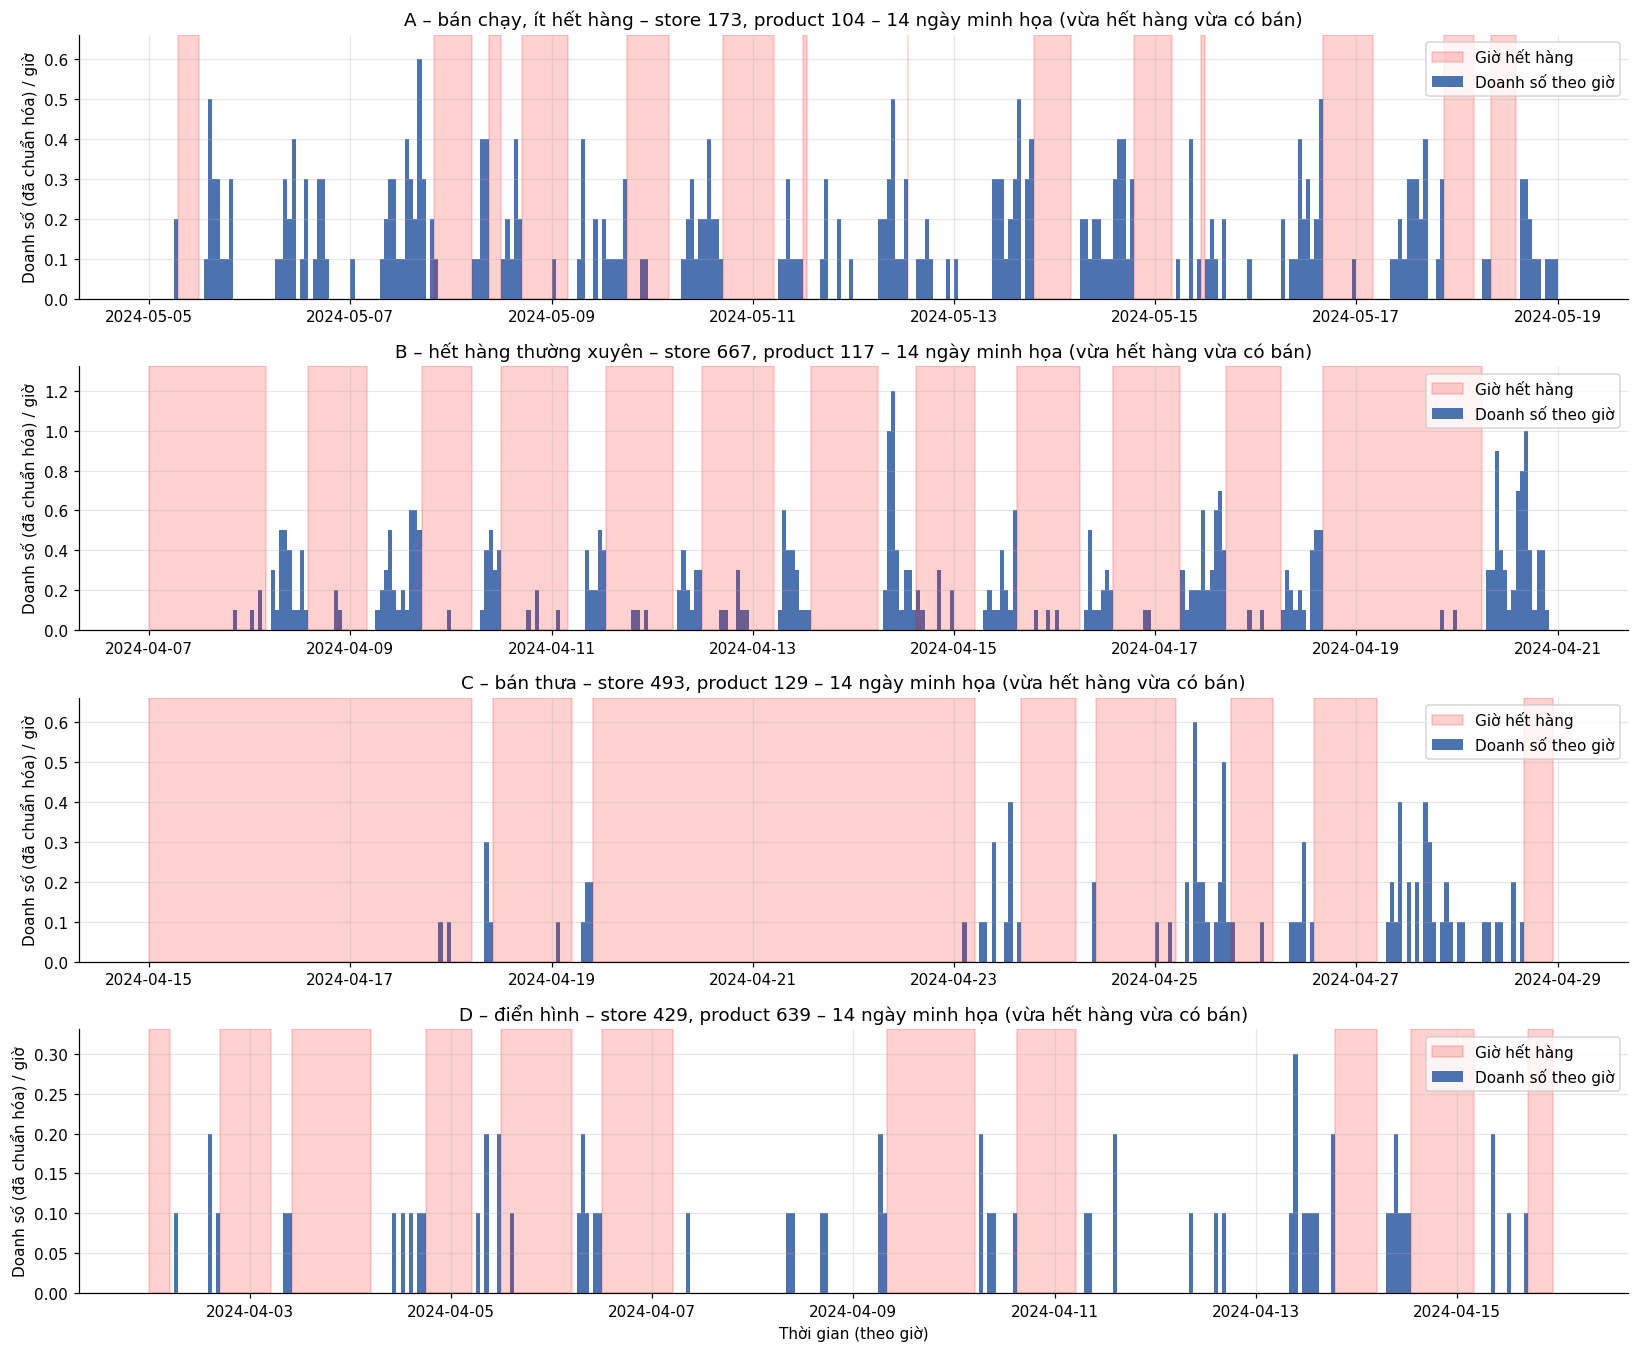

In [20]:
WIN = 14  # số ngày hiển thị theo giờ
fig, axes = plt.subplots(len(picked), 1, figsize=(15, 3.1 * len(picked)), squeeze=False)
for ax, (name, key) in zip(axes[:, 0], picked.items()):
    idx = series_rows(key)
    # chọn 14 ngày có nhiều ngày "vừa có giờ hết hàng (6..21) vừa có doanh số > 0" nhất
    mixed = ((stock_h[idx][:, BIZ_LO:BIZ_HI].sum(axis=1) > 0) & (sale_h[idx].sum(axis=1) > 0)).astype(int)
    start = int(np.argmax(np.convolve(mixed, np.ones(WIN), 'valid')))
    sel = idx[start:start + WIN]
    y = sale_h[sel].ravel(); st = stock_h[sel].ravel()
    t = pd.date_range(df['dt'].iloc[sel[0]], periods=len(y), freq='h')
    ax.bar(t, y, width=1 / 24, align='edge', color='#4C72B0', label='Doanh số theo giờ')
    ax.fill_between(t, 0, 1, where=st == 1, step='post', color='red', alpha=0.18,
                    transform=ax.get_xaxis_transform(), label='Giờ hết hàng')
    ax.set_ylim(bottom=0)
    ax.set_title(f'{name} – store {key[0]}, product {key[1]} – 14 ngày minh họa (vừa hết hàng vừa có bán)')
    ax.set_ylabel(SALE_LABEL + ' / giờ')
    ax.legend(loc='upper right')
axes[-1, 0].set_xlabel('Thời gian (theo giờ)')
fig.tight_layout(); save_fig(fig, '4a_chuoi_minh_hoa_theo_gio.png'); plt.show()

Đã lưu: /content/drive/MyDrive/FRN50K/figures/4b_chuoi_minh_hoa_theo_ngay.png


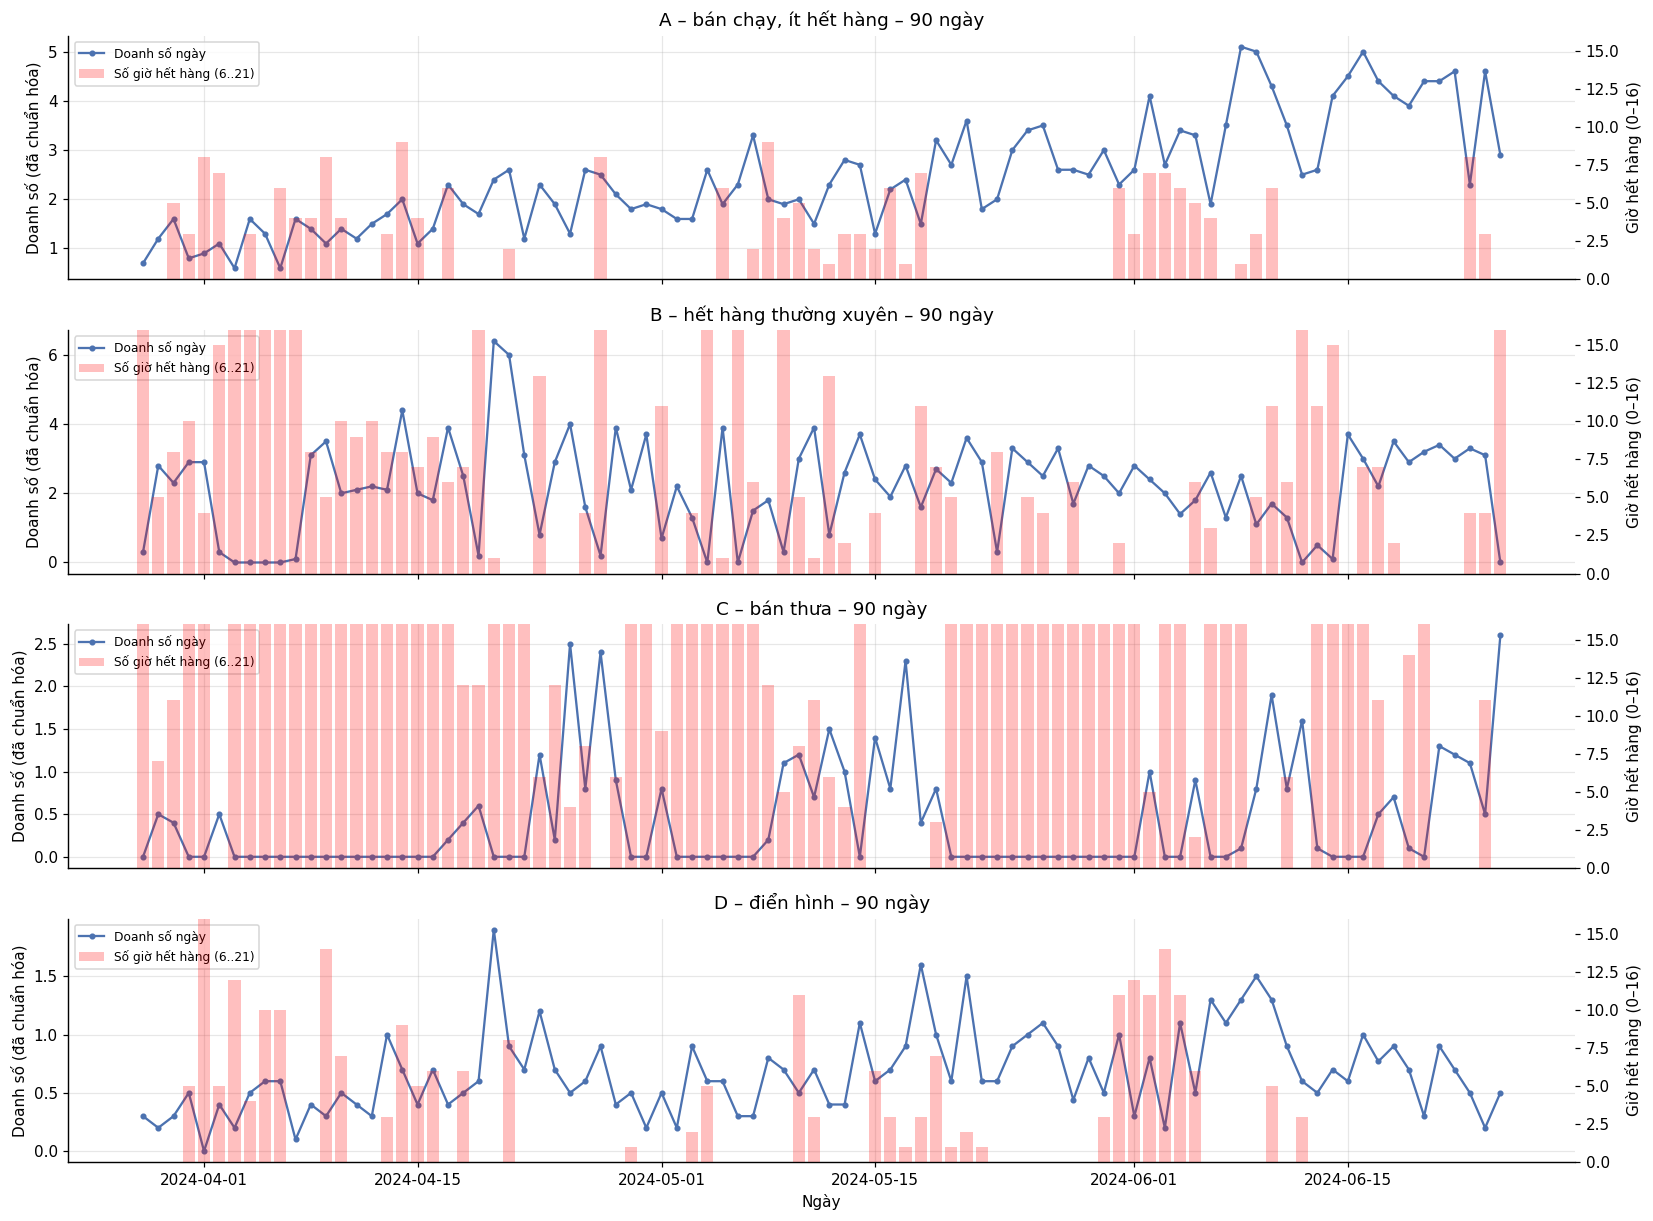

In [22]:
fig, axes = plt.subplots(len(picked), 1, figsize=(15, 2.8 * len(picked)), squeeze=False, sharex=True)
for ax, (name, key) in zip(axes[:, 0], picked.items()):
    idx = series_rows(key)
    d = df.iloc[idx]
    ax.plot(d['dt'], d['sale_amount'], marker='.', color='#4C72B0', label='Doanh số ngày')
    ax.set_ylabel(SALE_LABEL)
    ax2 = ax.twinx()
    ax2.bar(d['dt'], d['stock_hour6_22_cnt'], color='red', alpha=0.25, label='Số giờ hết hàng (6..21)')
    ax2.set_ylim(0, 16); ax2.set_ylabel('Giờ hết hàng (0–16)')
    ax2.grid(False)
    ax.set_title(f'{name} – 90 ngày')
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=8)
axes[-1, 0].set_xlabel('Ngày')
fig.tight_layout(); save_fig(fig, '4b_chuoi_minh_hoa_theo_ngay.png'); plt.show()

**Nhận xét phần 4**

Bốn chuỗi minh họa (chọn theo tiêu chí cố định, random_state = 42):

| Nhóm | store–product | Doanh số TB/ngày | Tỷ lệ ngày doanh số 0 | Tỷ lệ giờ hết hàng (6..21) |
|---|---|---|---|---|
| A – bán chạy, ít hết hàng | 173–104 | 2,45 | 0% | 13,5% |
| B – hết hàng thường xuyên | 667–117 | 2,18 | 8,9% | 36,9% |
| C – bán thưa | 493–129 | 0,42 | 55,6% | 71,7% |
| D – điển hình | 429–639 | 0,67 | 1,1% | 16,8% |

*Tiêu chí chọn: A thuộc 10% chuỗi bán chạy nhất và có tỷ lệ hết hàng thấp nhất trong nhóm đó (10% thấp nhất); B có tỷ lệ giờ hết hàng 30–60% và doanh số TB trên trung vị; C có ít nhất 50% số ngày doanh số bằng 0; D có doanh số TB và tỷ lệ hết hàng gần trung vị. Biểu đồ theo giờ hiển thị 14 ngày có nhiều ngày "vừa hết hàng vừa có bán" nhất của mỗi chuỗi.*

- **Doanh số trong giờ hết hàng:** trong vùng hết hàng, doanh số gần như luôn bằng 0; doanh số chỉ xuất hiện trong khoảng giờ còn hàng. Thỉnh thoảng có vài giờ vẫn có doanh số dù được đánh dấu hết hàng (thường là giờ đầu của đợt hết hàng), khớp với tỷ lệ 2,87% ở phần 1b.
- **Thời điểm hết hàng trong ngày:** đợt hết hàng thường bắt đầu vào buổi chiều hoặc tối, kéo dài qua đêm và kết thúc vào sáng hôm sau (sau khi nhập hàng) → hàng bán hết trong ngày và chờ nhập lại sáng hôm sau, phù hợp với dạng chữ U của tỷ lệ hết hàng theo giờ ở phần 2.
- **Doanh số bị cắt cụt rõ rệt (B):** khoảng 5 ngày đầu tháng 4 hết hàng gần đủ 16 giờ và doanh số ngày rơi về gần 0, trong khi các ngày còn hàng bán khoảng 2–4. Cuối kỳ ít hết hàng hơn thì doanh số ổn định quanh 3.
- **Bán thưa do thiếu hàng (C):** các đoạn dài doanh số bằng 0 trùng với các đoạn hết hàng cả 16 giờ; khi có hàng thì có bán (có ngày đến 2,5) → chuỗi này "bán thưa" phần lớn do thiếu hàng chứ không phải do ít nhu cầu. Nếu huấn luyện trên doanh số gốc, mô hình sẽ học nhu cầu thấp hơn thực tế ở những chuỗi như vậy.
- **Chuỗi bán chạy (A):** doanh số tăng liên tục từ khoảng 1/ngày (đầu tháng 4) lên khoảng 4–5/ngày (cuối tháng 6), minh họa rõ xu hướng tăng ở phần 3. Hết hàng ở chuỗi này ngắn (thường dưới 8 giờ/ngày) và doanh số không rơi về 0 vào những ngày đó.
- **Chuỗi điển hình (D):** hết hàng xảy ra rải rác, thường vài giờ mỗi lần; nhiều ngày có hết hàng vẫn bán ở mức bình thường.
- **Tóm lại:** mức ảnh hưởng của hết hàng phụ thuộc vào độ dài đợt hết hàng – hết hàng ngắn chỉ cắt bớt một phần doanh số, còn hết hàng cả ngày (B, C) làm doanh số gần như mất hẳn. Đây là lý do cần bước khôi phục nhu cầu tiềm ẩn trước khi dự báo.

## 5. Doanh số theo giảm giá, khuyến mãi, ngày lễ và thời tiết
**Lưu ý:** đây là **quan hệ quan sát được**, không phải quan hệ nhân quả. Ví dụ: khuyến mãi có thể được áp dụng cho mặt hàng/thời điểm vốn bán chạy; thời tiết khác nhau theo thành phố và mùa.

Để giảm ảnh hưởng của việc mỗi chuỗi có quy mô khác nhau, dùng **chỉ số doanh số tương đối**:
`rel = sale_amount / doanh số TB 90 ngày của chính chuỗi đó` (rel = 1,2 nghĩa là cao hơn mức bình thường của chuỗi 20%). Bỏ các chuỗi có doanh số TB = 0.
Ngoài ra tính riêng trên **ngày không hết hàng** để tránh doanh số bị cắt cụt.

In [23]:
mean_map = ser['mean_sale']
series_mean = pd.MultiIndex.from_arrays([df['store_id'], df['product_id']]).map(mean_map).to_numpy()
df['rel'] = np.where(series_mean > 0, df['sale_amount'].to_numpy() / np.where(series_mean > 0, series_mean, 1), np.nan)

def rel_table(group_col, order=None):
    t = df.groupby(group_col, observed=True).agg(
        so_dong=('rel', 'size'),
        doanh_so_tb=('sale_amount', 'mean'),
        rel_tb=('rel', 'mean'),
        ty_le_ngay_het_hang=('has_stockout', 'mean'))
    t['ty_trong_dong'] = t['so_dong'] / len(df)
    t['rel_tb_ngay_khong_het'] = df[~df['has_stockout']].groupby(group_col, observed=True)['rel'].mean()
    if order is not None:
        t = t.reindex([o for o in order if o in t.index])
    return t

# ---- Giảm giá: kiểm tra giá trị bất thường trước
d = df['discount']
anom = pd.Series({'discount = 0': int((d == 0).sum()),
                  'discount > 1': int((d > 1).sum()),
                  'discount = 1 (không giảm)': int(np.isclose(d, 1).sum()),
                  'discount < 1': int((d < 1).sum())}).to_frame('số dòng')
anom['tỷ lệ'] = anom['số dòng'] / len(df)
display(anom.style.format({'tỷ lệ': '{:.2%}'}))
save_tab(anom, '5a_discount_bat_thuong.csv')

conds = [d == 0, d > 1 + 1e-9, np.isclose(d, 1), d >= .9, d >= .8, d >= .7, d >= .5]
labels = ['=0 (bất thường)', '>1 (bất thường)', '1.0 (không giảm)', '[0.9;1)', '[0.8;0.9)', '[0.7;0.8)', '[0.5;0.7)']
df['disc_bin'] = np.select(conds, labels, default='(0;0.5)')
disc_order = ['1.0 (không giảm)', '[0.9;1)', '[0.8;0.9)', '[0.7;0.8)', '[0.5;0.7)', '(0;0.5)', '>1 (bất thường)', '=0 (bất thường)']
disc_tab = rel_table('disc_bin', disc_order)
act_tab  = rel_table('activity_flag'); act_tab.index = ['Không khuyến mãi (0)', 'Có khuyến mãi (1)'][:len(act_tab)]
hol_tab  = rel_table('holiday_flag');  hol_tab.index = ['Ngày thường (0)', 'Ngày lễ (1)'][:len(hol_tab)]
for name, t in [('5b_theo_giam_gia', disc_tab), ('5c_theo_khuyen_mai', act_tab), ('5d_theo_ngay_le', hol_tab)]:
    save_tab(t, name + '.csv')
print('Mức giảm giá = discount (1.0 = giá gốc, 0.8 = giảm 20%)')
display(disc_tab.round(3)); display(act_tab.round(3)); display(hol_tab.round(3))
print('Bảng chéo giảm giá × khuyến mãi (số dòng):')
display(pd.crosstab(df['disc_bin'], df['activity_flag']).reindex(disc_order).dropna(how='all'))

,số dòng,tỷ lệ
discount = 0,16039,0.36%
discount > 1,34,0.00%
discount = 1 (không giảm),2181121,48.47%
discount < 1,2318845,51.53%


Mức giảm giá = discount (1.0 = giá gốc, 0.8 = giảm 20%)


,so_dong,doanh_so_tb,rel_tb,ty_le_ngay_het_hang,ty_trong_dong,rel_tb_ngay_khong_het
disc_bin,,,,,,
1.0 (không giảm),2181121,0.8330,0.8870,0.4300,0.4850,0.9070
[0.9;1),724658,1.0240,1.0680,0.4350,0.1610,1.0660
[0.8;0.9),847707,0.9320,1.0510,0.4620,0.1880,1.0410
[0.7;0.8),429102,1.1380,1.1220,0.4600,0.0950,1.1570
[0.5;0.7),285453,1.3670,1.3260,0.4480,0.0630,1.3880
(0;0.5),15886,2.1600,1.5410,0.5380,0.0040,1.7350
>1 (bất thường),34,0.6350,1.5220,0.4120,0.0000,1.5760
=0 (bất thường),16039,14.4750,1.0370,0.7790,0.0040,1.4600


,so_dong,doanh_so_tb,rel_tb,ty_le_ngay_het_hang,ty_trong_dong,rel_tb_ngay_khong_het
Không khuyến mãi (0),2797107,0.9900,0.9310,0.4290,0.6220,0.9480
Có khuyến mãi (1),1702893,1.0130,1.1140,0.4650,0.3780,1.1290


,so_dong,doanh_so_tb,rel_tb,ty_le_ngay_het_hang,ty_trong_dong,rel_tb_ngay_khong_het
Ngày thường (0),2950000,0.9140,0.9220,0.4420,0.6560,0.9400
Ngày lễ (1),1550000,1.1600,1.1480,0.4440,0.3440,1.1560


Bảng chéo giảm giá × khuyến mãi (số dòng):


activity_flag,0,1
disc_bin,,
1.0 (không giảm),2142743,38378
[0.9;1),531730,192928
[0.8;0.9),78013,769694
[0.7;0.8),17905,411197
[0.5;0.7),10762,274691
(0;0.5),2,15884
>1 (bất thường),34,0
=0 (bất thường),15918,121


Đã lưu: /content/drive/MyDrive/FRN50K/figures/5a_giam_gia_khuyen_mai_ngay_le.png


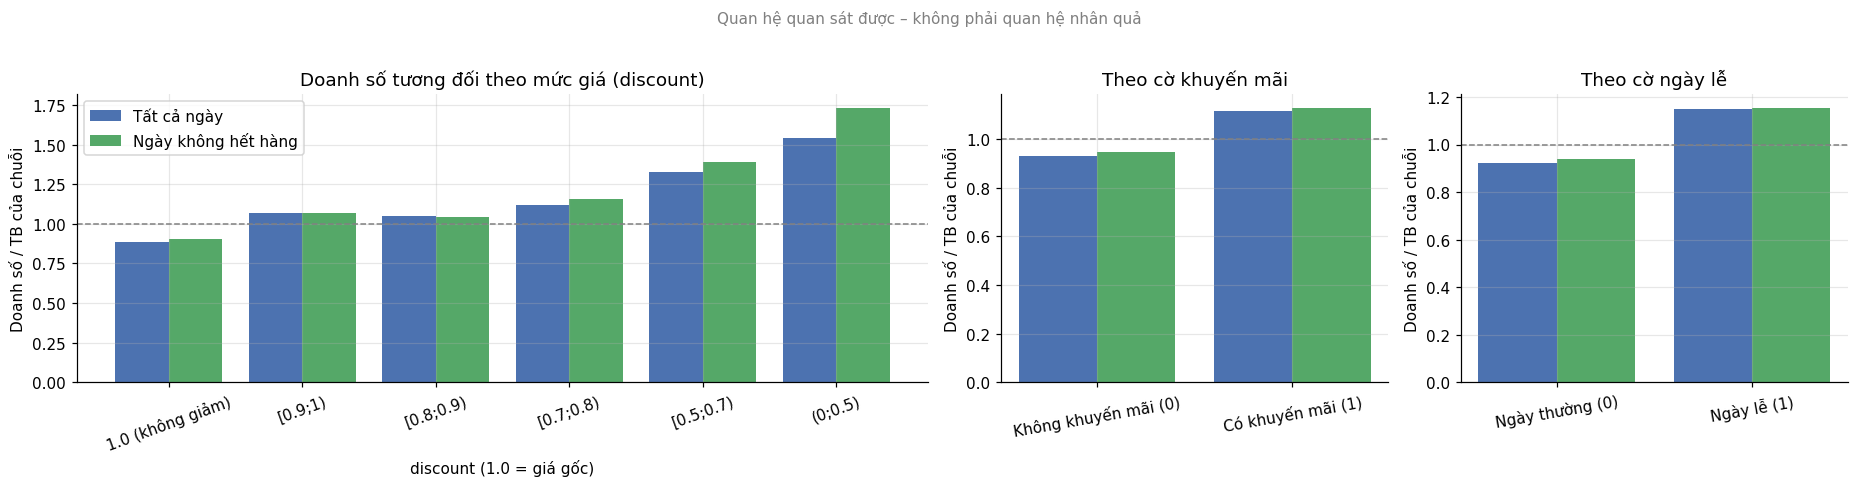

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), gridspec_kw={'width_ratios': [2.2, 1, 1]})
dt_ = disc_tab.drop(index=[i for i in disc_tab.index if 'bất thường' in i])
x = np.arange(len(dt_))
axes[0].bar(x - 0.2, dt_['rel_tb'], 0.4, label='Tất cả ngày', color='#4C72B0')
axes[0].bar(x + 0.2, dt_['rel_tb_ngay_khong_het'], 0.4, label='Ngày không hết hàng', color='#55A868')
axes[0].set_xticks(x); axes[0].set_xticklabels(dt_.index, rotation=20)
axes[0].axhline(1, color='gray', ls='--', lw=1)
axes[0].set_title('Doanh số tương đối theo mức giá (discount)')
axes[0].set_xlabel('discount (1.0 = giá gốc)'); axes[0].set_ylabel('Doanh số / TB của chuỗi'); axes[0].legend()
for ax, t, ttl in [(axes[1], act_tab, 'Theo cờ khuyến mãi'), (axes[2], hol_tab, 'Theo cờ ngày lễ')]:
    xx = np.arange(len(t))
    ax.bar(xx - 0.2, t['rel_tb'], 0.4, color='#4C72B0', label='Tất cả ngày')
    ax.bar(xx + 0.2, t['rel_tb_ngay_khong_het'], 0.4, color='#55A868', label='Ngày không hết hàng')
    ax.set_xticks(xx); ax.set_xticklabels(t.index, rotation=10)
    ax.axhline(1, color='gray', ls='--', lw=1); ax.set_title(ttl); ax.set_ylabel('Doanh số / TB của chuỗi')
fig.suptitle('Quan hệ quan sát được – không phải quan hệ nhân quả', y=1.02, fontsize=10, color='gray')
fig.tight_layout(); save_fig(fig, '5a_giam_gia_khuyen_mai_ngay_le.png'); plt.show()

In [25]:
# ---- Thời tiết: kiểm tra mức chi tiết trước (theo thành phố-ngày hay theo cửa hàng-ngày?)
w_cols = ['precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level']
lvl = df.groupby(['city_id', 'dt'])[w_cols].nunique().max()
print('Số giá trị thời tiết khác nhau lớn nhất trong cùng (thành phố, ngày):'); print(lvl.to_dict())
print('=> nếu = 1: thời tiết đo theo thành phố-ngày; nếu > 1: theo cửa hàng-ngày')

df['rain_bin'] = pd.cut(df['precpt'], [-0.01, 0, 1, 5, 10, 25, np.inf],
                        labels=['0', '(0;1]', '(1;5]', '(5;10]', '(10;25]', '>25'])
df['temp_bin'] = pd.qcut(df['avg_temperature'], 8, duplicates='drop')
df['hum_bin']  = pd.qcut(df['avg_humidity'], 5, duplicates='drop')
df['wind_bin'] = pd.qcut(df['avg_wind_level'], 5, duplicates='drop')
w_tabs = {'Lượng mưa (precpt)': rel_table('rain_bin'), 'Nhiệt độ TB (°C)': rel_table('temp_bin'),
          'Độ ẩm TB (%)': rel_table('hum_bin'), 'Mức gió TB': rel_table('wind_bin')}
for i, (k, t) in enumerate(w_tabs.items()):
    save_tab(t, f'5e_thoi_tiet_{i}.csv'); print(k); display(t.round(3))

Số giá trị thời tiết khác nhau lớn nhất trong cùng (thành phố, ngày):
{'precpt': 268, 'avg_temperature': 74, 'avg_humidity': 180, 'avg_wind_level': 32}
=> nếu = 1: thời tiết đo theo thành phố-ngày; nếu > 1: theo cửa hàng-ngày
Lượng mưa (precpt)


,so_dong,doanh_so_tb,rel_tb,ty_le_ngay_het_hang,ty_trong_dong,rel_tb_ngay_khong_het
rain_bin,,,,,,
0,8353,0.7490,0.9230,0.4180,0.0020,1.0220
(0;1],626110,0.9550,0.9840,0.4190,0.1390,1.0060
(1;5],2829289,0.9700,0.9700,0.4480,0.6290,0.9870
(5;10],673882,1.0870,1.0810,0.4270,0.1500,1.0790
(10;25],356715,1.1380,1.1130,0.4730,0.0790,1.1180
>25,5651,0.9680,0.9790,0.5560,0.0010,1.0520


Nhiệt độ TB (°C)


,so_dong,doanh_so_tb,rel_tb,ty_le_ngay_het_hang,ty_trong_dong,rel_tb_ngay_khong_het
temp_bin,,,,,,
"(12.059000000000001, 17.65]",563255,0.8500,0.8780,0.5140,0.1250,0.9000
"(17.65, 19.39]",566344,0.9060,0.9500,0.4880,0.1260,0.9860
"(19.39, 20.95]",558935,0.9670,0.9670,0.4340,0.1240,0.9890
"(20.95, 22.5]",569769,1.0050,0.9900,0.4390,0.1270,1.0090
"(22.5, 23.69]",557367,1.0460,1.0270,0.3860,0.1240,1.0190
"(23.69, 25.4]",559506,1.0330,1.0140,0.4060,0.1240,1.0150
"(25.4, 26.71]",564409,1.0550,1.0480,0.4390,0.1250,1.0500
"(26.71, 30.88]",560415,1.1280,1.1280,0.4330,0.1250,1.1240


Độ ẩm TB (%)


,so_dong,doanh_so_tb,rel_tb,ty_le_ngay_het_hang,ty_trong_dong,rel_tb_ngay_khong_het
hum_bin,,,,,,
"(27.349, 69.89]",903090,0.9620,1.0000,0.4020,0.2010,1.0190
"(69.89, 74.61]",898332,1.0190,0.9920,0.4220,0.2000,0.9890
"(74.61, 77.87]",900197,0.9670,0.9650,0.4570,0.2000,0.9810
"(77.87, 81.79]",898470,0.9550,0.9580,0.4720,0.2000,0.9790
"(81.79, 100.0]",899911,1.0900,1.0840,0.4610,0.2000,1.1020


Mức gió TB


,so_dong,doanh_so_tb,rel_tb,ty_le_ngay_het_hang,ty_trong_dong,rel_tb_ngay_khong_het
wind_bin,,,,,,
"(0.969, 1.4]",907032,0.9800,0.9970,0.4520,0.2020,1.0180
"(1.4, 1.55]",907750,1.0130,1.0120,0.4400,0.2020,1.0150
"(1.55, 1.73]",959919,1.0210,1.0090,0.4390,0.2130,1.0120
"(1.73, 2.05]",832537,1.0190,1.0060,0.4370,0.1850,1.0130
"(2.05, 3.85]",892762,0.9600,0.9760,0.4460,0.1980,1.0100


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [32]:
lvl_store = df.groupby(['store_id', 'dt'])[w_cols].nunique().max()
print('Số giá trị thời tiết khác nhau lớn nhất trong cùng (cửa hàng, ngày):', lvl_store.to_dict())
print('=> nếu = 1: thời tiết đo theo cửa hàng-ngày; nếu > 1: khác nhau cả giữa các sản phẩm trong cùng cửa hàng')

Số giá trị thời tiết khác nhau lớn nhất trong cùng (cửa hàng, ngày): {'precpt': 1, 'avg_temperature': 1, 'avg_humidity': 1, 'avg_wind_level': 1}
=> nếu = 1: thời tiết đo theo cửa hàng-ngày; nếu > 1: khác nhau cả giữa các sản phẩm trong cùng cửa hàng


Đã lưu: /content/drive/MyDrive/FRN50K/figures/5b_thoi_tiet.png


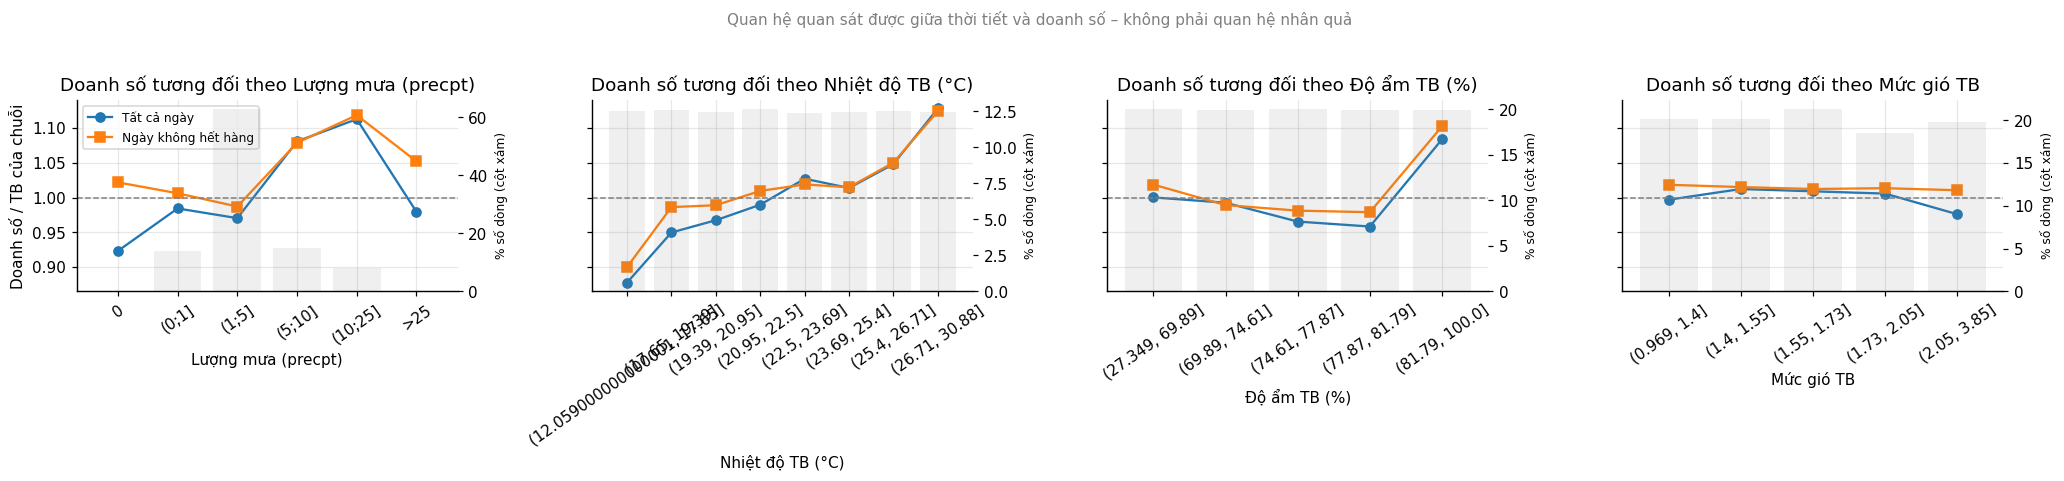

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2), sharey=True)
for ax, (k, t) in zip(axes, w_tabs.items()):
    lab = [str(i) for i in t.index]
    ax.plot(lab, t['rel_tb'], marker='o', label='Tất cả ngày')
    ax.plot(lab, t['rel_tb_ngay_khong_het'], marker='s', label='Ngày không hết hàng')
    ax.axhline(1, color='gray', ls='--', lw=1)
    ax.set_title(f'Doanh số tương đối theo {k}'); ax.set_xlabel(k)
    ax.tick_params(axis='x', rotation=35)
    ax2 = ax.twinx(); ax2.bar(lab, t['ty_trong_dong'] * 100, alpha=0.12, color='gray'); ax2.grid(False)
    ax2.set_ylabel('% số dòng (cột xám)', fontsize=8)
axes[0].set_ylabel('Doanh số / TB của chuỗi'); axes[0].legend(fontsize=8)
fig.suptitle('Quan hệ quan sát được giữa thời tiết và doanh số – không phải quan hệ nhân quả', y=1.03, fontsize=10, color='gray')
fig.tight_layout(); save_fig(fig, '5b_thoi_tiet.png'); plt.show()

Đã lưu: /content/drive/MyDrive/FRN50K/figures/5c_mua_theo_danh_muc.png


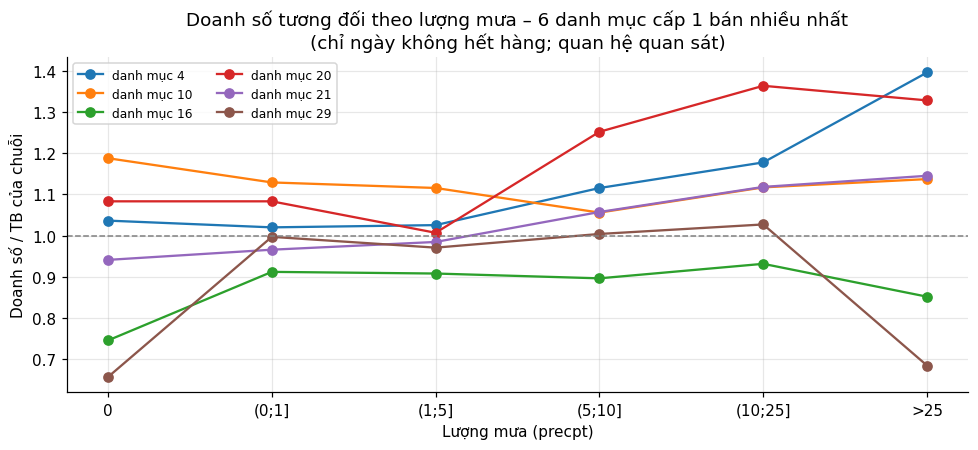

first_category_id,4,10,16,20,21,29
rain_bin,,,,,,
0,1.0360,1.1880,0.7450,1.0830,0.9410,0.6560
(0;1],1.0200,1.1290,0.9120,1.0830,0.9660,0.9970
(1;5],1.0250,1.1160,0.9080,1.0070,0.9840,0.9710
(5;10],1.1160,1.0560,0.8960,1.2520,1.0570,1.0040
(10;25],1.1780,1.1170,0.9310,1.3640,1.1180,1.0270
>25,1.3960,1.1370,0.8510,1.3280,1.1450,0.6840


In [27]:
# Mưa theo 6 danh mục cấp 1 bán nhiều nhất (bài báo nêu mưa gắn với nhu cầu rau tăng ~11%)
top_cat = by_cat.sort_values('ty_trong_doanh_so', ascending=False).head(6).index
sub = df[df['first_category_id'].isin(top_cat) & ~df['has_stockout']]
pv = sub.pivot_table(index='rain_bin', columns='first_category_id', values='rel', aggfunc='mean', observed=True)
save_tab(pv, '5f_mua_theo_danh_muc.csv')
fig, ax = plt.subplots(figsize=(9, 4.2))
for c in pv.columns:
    ax.plot(pv.index.astype(str), pv[c], marker='o', label=f'danh mục {c}')
ax.axhline(1, color='gray', ls='--', lw=1)
ax.set_title('Doanh số tương đối theo lượng mưa – 6 danh mục cấp 1 bán nhiều nhất\n(chỉ ngày không hết hàng; quan hệ quan sát)')
ax.set_xlabel('Lượng mưa (precpt)'); ax.set_ylabel('Doanh số / TB của chuỗi'); ax.legend(fontsize=8, ncol=2)
fig.tight_layout(); save_fig(fig, '5c_mua_theo_danh_muc.png'); plt.show()
pv.round(3)

**Nhận xét phần 5** (quan hệ quan sát được, không kết luận nhân quả; "chỉ số tương đối" = doanh số / TB 90 ngày của chính chuỗi; giá trị trong ngoặc: tất cả ngày / chỉ ngày không hết hàng)

- **Giảm giá:** 48,47% số dòng không giảm giá (discount = 1), 51,53% có discount < 1. Chỉ số tương đối tăng dần theo mức giảm: không giảm 0,89 / 0,91; giảm dưới 10% 1,07 / 1,07; giảm 10–20% 1,05 / 1,04; giảm 20–30% 1,12 / 1,16; giảm 30–50% 1,33 / 1,39; giảm trên 50% 1,54 / 1,74 (nhóm này chỉ chiếm 0,4% số dòng). Mức giảm càng sâu thì tỷ lệ ngày có hết hàng càng cao (43,0% khi không giảm, 53,8% khi giảm trên 50%) → doanh số lúc giảm giá sâu có thể còn bị cắt cụt nhiều hơn, nên chênh lệch thật có thể lớn hơn quan sát được.
- **Giảm giá và khuyến mãi gần như trùng nhau:** các dòng discount < 0,9 hầu như đều có activity_flag = 1; dòng không giảm giá hầu như có activity_flag = 0 → không tách được ảnh hưởng của giảm giá và cờ khuyến mãi.
- **Khuyến mãi:** 37,8% số dòng có khuyến mãi. Chỉ số tương đối 1,11 / 1,13 khi có khuyến mãi so với 0,93 / 0,95 khi không – cao hơn khoảng 20%. Bài báo báo cáo mức tăng trung vị 1,43 lần sau khi kiểm soát ngày lễ; cách tính khác nên không so trực tiếp. Có thể khuyến mãi được áp dụng cho mặt hàng/thời điểm vốn bán chạy.
- **Ngày lễ:** 31 ngày có holiday_flag = 1 (34,4% số dòng), chủ yếu là cuối tuần (xem phần 3). Chỉ số tương đối 1,15 / 1,16 so với 0,92 / 0,94 ngày thường – cao hơn khoảng 25%, gần bằng chênh lệch cuối tuần so với ngày thường → phản ánh chủ yếu hiệu ứng cuối tuần/ngày nghỉ. Tỷ lệ ngày có hết hàng gần như bằng nhau (44,4% và 44,2%).
- **Giá trị discount bất thường:** 16.039 dòng discount = 0 (0,36%) có doanh số TB 14,5/ngày – thuộc nhóm chuỗi bán rất nhiều – và chỉ số tương đối 1,04 (bình thường so với chính chuỗi), tỷ lệ ngày hết hàng 77,9% → nhiều khả năng là lỗi mã hóa/thiếu giá chứ không phải giảm 100%. 34 dòng discount > 1 (tối đa 1,088). Cần thống nhất cách xử lý trước khi đưa vào mô hình.
- **Lượng mưa:** chỉ 0,2% số dòng có precpt = 0; 62,9% nằm trong (1;5] → precpt có thể không phải lượng mưa mm/ngày thông thường. Chỉ số tương đối gần 1 ở mức mưa thấp, cao hơn ở (5;10] (1,08) và (10;25] (1,11 / 1,12); hai nhóm hai đầu (0 và >25) có rất ít dòng nên không đáng tin cậy. Tỷ lệ ngày hết hàng cao hơn khi mưa nhiều (47,3% ở (10;25], 55,6% ở >25).
- **Mưa theo danh mục:** khác nhau giữa các danh mục – danh mục 4 và 20 tăng rõ khi mưa nhiều (lên khoảng 1,36–1,40), danh mục 21 tăng nhẹ, danh mục 10 giảm nhẹ, danh mục 16 gần như không đổi. Không biết tên danh mục (đã mã hóa) nên không kiểm tra được nhận định của bài báo về rau (+11% khi mưa).
- **Nhiệt độ:** chỉ số tương đối tăng gần như đều từ 0,88 (12–17,7°C) lên 1,13 (26,7–30,9°C); tỷ lệ ngày hết hàng giảm từ 51,4% xuống khoảng 43%. Nhiệt độ tăng dần từ tháng 3 đến tháng 6, cùng chiều với xu hướng tăng doanh số (phần 3) → quan hệ này nhiều khả năng lẫn với xu hướng thời gian.
- **Độ ẩm và gió:** chỉ số tương đối gần như không đổi (khoảng 0,96–1,02) giữa các nhóm; riêng nhóm độ ẩm cao nhất (81,8–100%) cao hơn (1,08 / 1,10).

## 6. Tổng hợp số liệu chính (dùng cho phần “Mô tả dữ liệu” trong báo cáo)

In [28]:
KEY.update({
    'so_dong_train': N_ROWS, 'so_chuoi': len(ser),
    'so_thanh_pho': int(df['city_id'].nunique()), 'so_cua_hang': int(df['store_id'].nunique()),
    'so_san_pham': int(df['product_id'].nunique()),
    'ngay_dau': str(df['dt'].min().date()), 'ngay_cuoi': str(df['dt'].max().date()),
    'so_ngay': int(df['dt'].nunique()),
    'doanh_so_ngay_trung_vi': float(df['sale_amount'].median()),
    'doanh_so_ngay_TB': float(df['sale_amount'].mean()),
    'gio_het_hang_cao_nhat': int(hr_rate.argmax()), 'ty_le_het_hang_gio_cao_nhat_%': float(hr_rate.max()),
    'gio_het_hang_thap_nhat': int(hr_rate.argmin()), 'ty_le_het_hang_gio_thap_nhat_%': float(hr_rate.min()),
    'so_ngay_le': int((daily['holiday'] > 0.5).sum()),
    'ty_le_dong_discount_bat_thuong': float(((d == 0) | (d > 1 + 1e-9)).mean()),
    'ty_le_dong_co_khuyen_mai': float(df['activity_flag'].mean()),
})
KEY = {k: (float(v) if isinstance(v, (np.floating, np.integer)) else v) for k, v in KEY.items()}
with open(os.path.join(TAB_DIR, '6_so_lieu_chinh.json'), 'w', encoding='utf-8') as f:
    json.dump(KEY, f, ensure_ascii=False, indent=2)
pd.Series(KEY).to_frame('giá trị')

,giá trị
ty_le_ngay_doanh_so_0,0.0446
ty_le_gio_doanh_so_0_24h,0.7778
top20_chuoi_chiem_ty_le_doanh_so,0.4854
top20_product_id_chiem,0.8700
top20_store_id_chiem,0.3962
ty_le_gio_het_hang_6_21,0.1988
ty_le_gio_het_hang_24h,0.2489
ty_le_ngay_co_het_hang_6_21,0.4427
so_dong_train,4500000
so_chuoi,50000


In [30]:
print('Biểu đồ đã lưu:'); [print(' -', f) for f in sorted(os.listdir(FIG_DIR))]
print('Bảng đã lưu:');   [print(' -', f) for f in sorted(os.listdir(TAB_DIR))]

Biểu đồ đã lưu:
 - 1c_khac_biet_giua_chuoi.png
 - 2a_het_hang_phan_phoi_va_theo_gio.png
 - 2b_het_hang_theo_nhom.png
 - 3a_doanh_so_theo_thoi_gian.png
 - 3b_doanh_so_theo_gio.png
 - 3c_doanh_so_theo_thu.png
 - 4a_chuoi_minh_hoa_theo_gio.png
 - 4b_chuoi_minh_hoa_theo_ngay.png
 - 5a_giam_gia_khuyen_mai_ngay_le.png
 - 5b_thoi_tiet.png
 - 5c_mua_theo_danh_muc.png
Bảng đã lưu:
 - 1a_mo_ta_doanh_so_ngay.csv
 - 1b_doanh_so_0_va_het_hang_gio.csv
 - 1b_doanh_so_0_va_het_hang_ngay.csv
 - 1c_khac_biet_giua_chuoi.csv
 - 2a_thong_ke_het_hang.csv
 - 2a_ty_le_het_hang_theo_gio.csv
 - 2b_het_hang_theo_danh_muc1.csv
 - 2b_het_hang_theo_thanh_pho.csv
 - 3a_theo_ngay.csv
 - 3b_doanh_so_theo_gio.csv
 - 3c_theo_thu_trong_tuan.csv
 - 4_chuoi_minh_hoa.csv
 - 5a_discount_bat_thuong.csv
 - 5b_theo_giam_gia.csv
 - 5c_theo_khuyen_mai.csv
 - 5d_theo_ngay_le.csv
 - 5e_thoi_tiet_0.csv
 - 5e_thoi_tiet_1.csv
 - 5e_thoi_tiet_2.csv
 - 5e_thoi_tiet_3.csv
 - 5f_mua_theo_danh_muc.csv
 - 6_so_lieu_chinh.json


[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

## Mô tả dữ liệu

### 1. Nguồn và cấu trúc
Đồ án sử dụng bộ dữ liệu FreshRetailNet-50K do Dingdong-Inc công bố trên HuggingFace (giấy phép CC BY 4.0), gồm hai tập có sẵn: train (4.500.000 dòng) và eval (350.000 dòng). Mỗi dòng là một cặp cửa hàng–sản phẩm trong một ngày, gồm 19 cột: mã định danh (thành phố, cửa hàng, nhóm quản lý, danh mục cấp 1/2/3, sản phẩm), ngày, doanh số ngày (`sale_amount`), doanh số theo 24 giờ (`hours_sale`), trạng thái hết hàng theo 24 giờ (`hours_stock_status`), số giờ hết hàng trong ngày (`stock_hour6_22_cnt`), mức giá (`discount`), cờ ngày lễ (`holiday_flag`), cờ khuyến mãi (`activity_flag`) và bốn biến thời tiết (lượng mưa, nhiệt độ, độ ẩm, mức gió). Phần phân tích dưới đây thực hiện trên tập train; tập eval chỉ được kiểm tra cấu trúc và độ bao phủ.

Kiểm tra dữ liệu cho thấy: không có giá trị thiếu; mọi dòng có đủ 24 giờ; `sale_amount` bằng tổng `hours_sale` ở 100% số dòng; không có doanh số âm. Trong `hours_stock_status`, giá trị 1 là hết hàng và 0 là còn hàng (ngược với ký hiệu trong bài báo gốc); `stock_hour6_22_cnt` đếm số giờ hết hàng trong khung 6:00–21:59 (16 giờ). Doanh số đã được chuẩn hóa bằng một hệ số không công bố nên không có đơn vị thật, và doanh số ngày được làm tròn đến 0,1.

### 2. Quy mô
| Chỉ tiêu | Train | Eval |
|---|---|---|
| Số dòng | 4.500.000 | 350.000 |
| Số chuỗi cửa hàng–sản phẩm | 50.000 | 50.000 (100% có trong train) |
| Số thành phố / cửa hàng / sản phẩm | 18 / 898 / 865 | – |
| Số danh mục cấp 1 / 2 / 3 | 32 / 84 / 233 | – |
| Khoảng thời gian | 28/03/2024 – 25/06/2024 (90 ngày) | 26/06/2024 – 02/07/2024 (7 ngày) |

Dữ liệu là một bảng cân đối: cả 50.000 chuỗi đều có đủ 90 ngày, không thiếu ngày nào; mỗi cửa hàng thuộc đúng một thành phố. Tập eval là 7 ngày nối tiếp ngay sau train, không trùng ngày → bài toán là dự báo 7 ngày tiếp theo cho cùng các chuỗi. Phân bố giữa các thành phố rất lệch: thành phố 0 chiếm 51,6% số dòng.

### 3. Doanh số
Doanh số ngày lệch phải mạnh: trung bình 0,999, trung vị 0,7, độ lệch chuẩn 1,41, lớn nhất 44,9, skewness 8,47; 99% số dòng có doanh số không quá 5,8 (Hình 1a). 4,46% số dòng có doanh số ngày bằng 0, nhưng ở mức giờ dữ liệu rất thưa: 69,06% số giờ trong khung 6..21 (mẫu số 72.000.000 giờ) và 77,78% số giờ tính trên 24 giờ có doanh số bằng 0.

Mức độ khác biệt giữa các chuỗi lớn: doanh số trung bình/ngày của chuỗi có trung vị 0,66 và chênh 4,2 lần giữa phân vị 90% và 10%; hệ số biến thiên theo ngày của đa số chuỗi nằm trong khoảng 0,4–0,7 (Hình 1c). Doanh số tập trung: 20% chuỗi chiếm 48,5% tổng doanh số, 20% sản phẩm chiếm 87%. Không chuỗi nào có doanh số trung bình dưới 0,22/ngày và phân phối bị cắt rõ ở khoảng 0,4, gợi ý bộ dữ liệu đã được lọc chỉ giữ các chuỗi bán thường xuyên.

### 4. Hết hàng
Hết hàng xảy ra phổ biến. Trong khung 6..21, 19,88% số giờ là hết hàng (mẫu số 4.500.000 dòng × 16 giờ = 72.000.000 giờ); 44,27% số cửa hàng–sản phẩm–ngày có ít nhất một giờ hết hàng (mẫu số 4.500.000); 4,04% số ngày hết hàng cả 16 giờ; ngày có hết hàng trung bình hết 7,18 giờ. Tất cả 50.000 chuỗi đều có hết hàng, với tỷ lệ giờ hết hàng của từng chuỗi từ 3,9% đến 97% (trung vị 17,7%). Nếu tính trên 24 giờ, tỷ lệ giờ hết hàng là 24,89% và tỷ lệ ngày có hết hàng là 60,02%, do 46,8% số giờ hết hàng rơi vào ban đêm – lúc gần như không có doanh số – nên báo cáo dùng khung 6..21 làm chỉ số chính.

Theo giờ trong ngày, tỷ lệ hết hàng có dạng chữ U: cao vào ban đêm, giảm mạnh lúc 5–6h (thời điểm nhập hàng), thấp nhất lúc 7h (5,0%) rồi tăng dần đến cao nhất lúc 22h (41,9%) (Hình 2a); hình dạng này giống bài báo nhưng mức cụ thể khác. Tỷ lệ hết hàng khá đồng đều giữa các thành phố (18,9%–22,6%) và giữa các danh mục lớn (16%–22%) (Hình 2b).

Hết hàng làm doanh số bị cắt cụt: tỷ lệ ngày doanh số bằng 0 là 7,72% ở ngày có hết hàng so với 1,87% ở ngày không hết hàng, và 76,6% số ngày doanh số bằng 0 rơi vào ngày có hết hàng; 97,13% số giờ hết hàng có doanh số bằng 0. Các chuỗi minh họa (Hình 4a, 4b) cho thấy đợt hết hàng thường bắt đầu vào chiều tối, kéo qua đêm và kết thúc sau khi nhập hàng buổi sáng; hết hàng ngắn chỉ cắt bớt một phần doanh số, còn hết hàng cả ngày làm doanh số gần như về 0. Có chuỗi "bán thưa" mà các ngày doanh số bằng 0 trùng với các ngày hết hàng cả ngày, tức số 0 phản ánh thiếu hàng chứ không phải không có nhu cầu.

### 5. Mẫu hình theo thời gian
Tổng doanh số có xu hướng tăng khoảng 50% trong 90 ngày, trong khi tỷ lệ hết hàng giảm dần từ đỉnh khoảng 37% đầu tháng 4 xuống 15–20% từ giữa tháng 5 (Hình 3a). Chu kỳ tuần rõ rệt: doanh số trung bình thứ Bảy và Chủ nhật cao hơn mức chung 18–20%, các ngày trong tuần ở mức 0,87–0,96 lần (Hình 3c). Trong ngày, doanh số gần bằng 0 từ 0h–5h; ngày thường có hai đỉnh lúc 9h và 16h, cuối tuần có một đỉnh sáng 9h mạnh hơn hẳn (Hình 3b), khớp với mô tả của bài báo.

### 6. Biến ngoại sinh (quan hệ quan sát được, không phải quan hệ nhân quả)
Để loại bỏ khác biệt quy mô giữa các chuỗi, doanh số được so sánh qua chỉ số tương đối = doanh số ngày / doanh số trung bình 90 ngày của chính chuỗi đó (Hình 5a, 5b, 5c).
- **Giảm giá và khuyến mãi:** 51,53% số dòng có giảm giá; chỉ số tương đối tăng theo mức giảm, từ 0,89 khi không giảm lên 1,33 khi giảm 30–50%. Ngày có cờ khuyến mãi (37,8% số dòng) có chỉ số tương đối cao hơn khoảng 20% so với ngày không khuyến mãi. Giảm giá và cờ khuyến mãi gần như trùng nhau nên không tách được ảnh hưởng riêng. 0,36% số dòng có discount = 0 và 34 dòng có discount > 1 – nhiều khả năng là lỗi mã hóa.
- **Ngày lễ:** `holiday_flag` đánh dấu 31 ngày, gồm gần như mọi cuối tuần và các kỳ nghỉ lễ (Thanh Minh, Lao động); chỉ số tương đối những ngày này cao hơn khoảng 25%, chủ yếu phản ánh hiệu ứng ngày nghỉ.
- **Thời tiết:** đo theo cửa hàng–ngày. Doanh số tương đối cao hơn ở mức mưa vừa (5–25) và ở nhiệt độ cao, gần như không đổi theo độ ẩm và gió. Tuy nhiên lượng mưa hiếm khi bằng 0 (0,2% số dòng) nên ý nghĩa đơn vị chưa rõ, và nhiệt độ tăng dần theo mùa cùng chiều với xu hướng doanh số nên quan hệ với nhiệt độ có thể chỉ phản ánh xu hướng thời gian.

### 7. Hàm ý cho bước dự báo
(1) Doanh số gốc bị cắt cụt ở mức đáng kể và có hệ thống, nên mô hình huấn luyện trực tiếp trên doanh số gốc dễ dự báo thiếu – đây là cơ sở cho bước khôi phục nhu cầu tiềm ẩn. (2) Dữ liệu không dừng và có chu kỳ tuần mạnh; tập eval nằm ở giai đoạn doanh số cao nhất. (3) Doanh số tập trung vào một số chuỗi và một thành phố, nên chỉ số đánh giá tổng hợp (WAPE) chịu ảnh hưởng lớn của các nhóm này. Danh sách đầy đủ các đặc điểm cần lưu ý khi giải thích kết quả tái lập được trình bày ở phần tiếp theo.

## Đặc điểm dữ liệu cần lưu ý khi giải thích kết quả tái lập
*(Tất cả số liệu tính trên tập train: 4.500.000 dòng cửa hàng–sản phẩm–ngày, 50.000 chuỗi, 28/03–25/06/2024. "→" là ảnh hưởng và cách xử lý đề xuất.)*

### A. Cấu trúc và quy ước dữ liệu
1. **Mã hóa hết hàng ngược với ký hiệu của bài báo:** trong dữ liệu `hours_stock_status` = 1 là hết hàng; trong bài báo s = 1 là còn hàng. → Khi dùng code khôi phục nhu cầu phải kiểm tra chiều mã hóa; nếu đảo ngược, mặt nạ dữ liệu thiếu sẽ sai hoàn toàn.
2. **Tên cột `stock_hour6_22_cnt` dễ hiểu nhầm:** cột này đếm giờ 6..21 (16 giờ), không gồm giờ 22 (khớp 100% khi kiểm tra).
3. **Doanh số đã chuẩn hóa, không có đơn vị thật;** doanh số ngày có vẻ được làm tròn đến 0,1. → Chỉ so sánh chỉ số tương đối (WAPE, độ lệch %); không diễn giải MAE/RMSE thành số lượng hay tiền; phần "doanh thu bị mất" chỉ ước tính được ở dạng tương đối.
4. **Số sản phẩm đếm được là 865, bài báo ghi 863.** → Báo cáo dùng số liệu đếm từ dữ liệu tải về.
5. **Eval là 7 ngày ngay sau train (26/06–02/07/2024),** cùng 50.000 chuỗi, không trùng ngày. → Kết quả eval chỉ phản ánh 1 tuần, chứa đúng 1 cuối tuần.

### B. Hết hàng và doanh số bị cắt cụt
6. **Tỷ lệ hết hàng phụ thuộc vào khung giờ và mẫu số:** 19,88% số giờ khi tính giờ 6..21 (mẫu số 72.000.000 giờ) nhưng 24,89% khi tính 24 giờ (108.000.000 giờ); 44,27% số ngày có ít nhất 1 giờ hết hàng (6..21) nhưng 60,02% nếu tính 24 giờ. 46,8% số giờ hết hàng rơi vào ban đêm, lúc gần như không có doanh số. → Mọi con số hết hàng phải ghi kèm khung giờ và mẫu số; dùng khung 6..21 làm chỉ số chính.
7. **Số liệu hết hàng theo giờ khác bài báo:** cùng dạng chữ U nhưng thấp nhất 5,0% (7h) và cao nhất 41,9% (22h), trong khi bài báo ghi dưới 2% sau 6h và đỉnh 26% lúc 20h. → Bài báo có thể dùng tập con/cách tính khác; không dùng các con số đó làm chuẩn so sánh trực tiếp.
8. **Hết hàng rất phổ biến:** 100% chuỗi có hết hàng (tỷ lệ giờ hết hàng mỗi chuỗi từ 3,9% đến 97%, trung vị 17,7%); 76,6% số ngày doanh số = 0 rơi vào ngày có hết hàng. → Doanh số gốc đánh giá thấp nhu cầu một cách có hệ thống; mô hình học trên doanh số gốc dễ dự báo thiếu (độ lệch âm) – đúng điều bài báo cần kiểm chứng.
9. **Mức ảnh hưởng tùy độ dài đợt hết hàng:** hết hàng vài giờ chỉ cắt bớt một phần doanh số; hết hàng cả ngày (4,04% số ngày hết đủ 16 giờ) làm doanh số gần như về 0. Có chuỗi "bán thưa" (ví dụ store 493–product 129: 55,6% ngày doanh số 0) mà số 0 trùng với các ngày hết hàng cả ngày → bán thưa do thiếu hàng chứ không phải ít nhu cầu.
10. **2,87% giờ hết hàng vẫn có doanh số > 0** (có thể bán xong rồi mới hết trong cùng giờ). → Trạng thái theo giờ không hoàn toàn chính xác; là một nguồn sai số của bước khôi phục nhu cầu.
11. **Dữ liệu theo giờ rất thưa:** 69,06% số giờ trong khung 6..21 có doanh số = 0 (77,78% nếu tính 24 giờ). → Khôi phục nhu cầu theo giờ khó; sai số mức giờ có thể lớn dù tổng theo ngày vẫn hợp lý.
12. **Giảm giá sâu đi kèm hết hàng nhiều hơn** (43,0% ngày có hết hàng khi không giảm giá, 53,8% khi giảm trên 50%). → Doanh số lúc khuyến mãi bị cắt cụt nhiều hơn; mức tăng doanh số do khuyến mãi quan sát được có thể thấp hơn thực tế.

### C. Phân bố và mức độ đại diện
13. **Thành phố 0 chiếm 51,6% số dòng (2.322.990/4.500.000).** → Chỉ số tổng hợp chủ yếu phản ánh thành phố 0; nên báo cáo thêm kết quả theo thành phố (ít nhất tách thành phố 0 và các thành phố còn lại).
14. **Bộ dữ liệu có vẻ đã được lọc chuỗi:** không chuỗi nào có doanh số TB dưới 0,22/ngày, phân phối bị cắt rõ ở khoảng 0,4; không chuỗi nào bán 0 cả 90 ngày; mọi chuỗi đều có hết hàng. → Kết quả chỉ đại diện cho các chuỗi bán tương đối thường xuyên.
15. **Doanh số tập trung:** 20% sản phẩm chiếm 87% tổng doanh số (20% chuỗi chiếm 48,5%, 20% cửa hàng chiếm 39,6%); có một cụm nhỏ chuỗi bán rất nhiều (khoảng 15–19/ngày). → WAPE tính theo tổng bị chi phối bởi các chuỗi bán chạy; nên xem thêm kết quả theo nhóm doanh số. Bài báo báo cáo "top 20% SKU chiếm 51,8% giao dịch" – khác thước đo nên không so trực tiếp.
16. **Phân phối doanh số lệch phải mạnh:** trung bình 0,999, trung vị 0,7, skewness 8,47, lớn nhất 44,9. → RMSE nhạy với các ngày bán đột biến; nên ưu tiên WAPE/MAE khi so sánh.

### D. Thời gian và lịch
17. **Dữ liệu không dừng:** tổng doanh số tăng khoảng 50% trong 90 ngày (trung bình trượt 7 ngày từ khoảng 40.000 lên khoảng 60.000), trong khi tỷ lệ hết hàng giảm dần (đỉnh khoảng 37% đầu tháng 4, còn 15–20% từ giữa tháng 5). → Eval nằm ở giai đoạn doanh số cao nhất, mô hình dễ dự báo thiếu; một phần mức tăng có thể do ít bị cắt cụt hơn chứ không hoàn toàn do nhu cầu tăng.
18. **Chu kỳ tuần mạnh:** T7, CN cao hơn TB 18–20%; ngày thường có hai đỉnh giờ (9h, 16h), cuối tuần có một đỉnh sáng 9h mạnh hơn hẳn. → Sai số dự báo cuối tuần có thể chi phối kết quả eval.
19. **`holiday_flag` thực chất là cờ "ngày nghỉ":** đánh dấu 31 ngày, gồm gần như mọi cuối tuần cộng kỳ nghỉ Thanh Minh (4–6/4) và Lao động (1–5/5). → Không tách được hiệu ứng ngày lễ khỏi cuối tuần; nếu TFT cho thấy biến này quan trọng thì đó chủ yếu là hiệu ứng ngày nghỉ.

### E. Biến ngoại sinh
20. **`discount` có giá trị bất thường:** 16.039 dòng = 0 (0,36%) – thuộc nhóm chuỗi bán rất nhiều (doanh số TB 14,5/ngày), doanh số bình thường so với chính chuỗi → nhiều khả năng là lỗi mã hóa/thiếu giá, không phải giảm 100%; 34 dòng > 1 (tối đa 1,088). → Nhóm cần thống nhất cách xử lý (loại, thay bằng 1, hoặc giữ kèm cờ) trước khi huấn luyện và ghi rõ trong báo cáo.
21. **Giảm giá và cờ khuyến mãi gần như trùng nhau** (discount < 0,9 hầu như luôn có activity_flag = 1). → Không tách được ảnh hưởng riêng; độ quan trọng của hai biến trong mô hình có thể chia nhau tùy ý.
22. **Thời tiết đo theo cửa hàng–ngày:** trong cùng cửa hàng và ngày, mỗi biến thời tiết chỉ có 1 giá trị; trong cùng thành phố và ngày có thể có tới 268 giá trị lượng mưa, 74 giá trị nhiệt độ khác nhau. → Mọi sản phẩm trong cùng cửa hàng dùng chung thời tiết; khi gộp theo thành phố phải tính trung bình chứ không lấy một giá trị đại diện.
23. **`precpt` bất thường:** chỉ 0,2% số dòng có lượng mưa = 0, 62,9% nằm trong khoảng (1;5] → có thể không phải lượng mưa mm/ngày thông thường; hai nhóm mưa cực trị (0 và trên 25) có rất ít dòng. → Thận trọng khi diễn giải; không so trực tiếp với nhận định "mưa làm nhu cầu rau tăng 11%" của bài báo (danh mục đã mã hóa, không biết đâu là rau).
24. **Nhiệt độ lẫn với xu hướng thời gian:** doanh số tương đối tăng từ 0,88 (12–17,7°C) lên 1,13 (26,7–30,9°C), nhưng nhiệt độ cũng tăng dần từ tháng 3 đến tháng 6 cùng chiều với xu hướng doanh số. → Không kết luận nhiệt độ ảnh hưởng đến doanh số.
25. **Mọi quan hệ ở phần 5 là quan sát được, không phải nhân quả:** khuyến mãi (+20% so với không khuyến mãi), ngày nghỉ (+25%), mưa, nhiệt độ đều có thể bị nhiễu bởi lựa chọn mặt hàng, thời điểm và thành phố.